In [2]:
CATEGORY_MAP = {
    "gryffindor": "Gryffindor",
    "gryff": "Gryffindor",
    "slytherin": "Slytherin",
    "slyth": "Slytherin",
    "ravenclaw": "Ravenclaw",
    "raven": "Ravenclaw",
    "huffle": "Hufflepuff",
    "hufflepuff": "Hufflepuff",
    "staff": "Hogwarts Staff",
    "frog": "Chocolate Frog Card",
    "mom": "Ministry of Magic",
    "da": "Dumbledore’s Army",
    "de": "Death Eater",
    "ootp": "Order of the Phoenix",
    "quidd": "Quidditch Player",
    "quidditch": "Quidditch Player",
    "slug": "Slug Club",
    "slug club": "Slug Club",
    "black": "Related to the Blacks"
}

In [82]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re



def normalize_dashes(text):
    """
    Convierte guiones unicode a '-' ASCII:
    – (EN DASH), — (EM DASH), − (minus sign)
    """
    if not isinstance(text, str):
        return text
    return (
        text.replace("–", "-")
            .replace("—", "-")
            .replace("−", "-")
    )

class MagicalMenagerieScraper:

    def __init__(self, url):
        self.url = url
        self.characters = []
        self.soup = None

    def fetch(self):
        resp = requests.get(self.url)
        resp.raise_for_status()
        self.soup = BeautifulSoup(resp.text, "html.parser")

    def parse(self):
        for p in self.soup.select("p"):
            strong = p.find("strong")
            if not strong:
                continue

            # Categorías por imagen
            raw_categories = [img.get("alt") for img in p.find_all("img") if img.get("alt")]
            categories = [CATEGORY_MAP.get(cat, cat) for cat in raw_categories]

            # Nombre base del <strong>
            raw_name = normalize_dashes(strong.get_text(strip=True))
            clean_name = raw_name.rstrip("-").strip()

            # Descripción
            description = p.get_text(" ", strip=True)
            description = normalize_dashes(description)
            description = description.replace(raw_name, "").strip()

            self.characters.append({
                "name": clean_name,
                "full_name": clean_name,
                "description": description,
                "categories": categories
            })

    def preprocess_df(self, df):
        """
        Detecta nombres en descripción con:
        - Apellido, Nombre - desc     (con paréntesis permitidos)
        - Nombre Completo - desc      (nombres compuestos permitidos)
        Permite ? y elimina la última fila.
        """
        
        # Bloque de nombre/apellido, incluye puntos y caracteres especiales
        NAME_BLOCK = r"[A-Za-zÁÉÍÓÚÜÖÑñ0-9'´`‘’\"“”()\-\s?.]+" 
    
        patterns = [
            # Apellido, Nombre - desc
            re.compile(
                rf"^(?P<last>{NAME_BLOCK})\s*,\s*(?P<first>{NAME_BLOCK})\s*-\s*(?P<desc>.*)$",
                re.UNICODE
            ),
            # Nombre Completo - desc
            re.compile(
                rf"^(?P<name>{NAME_BLOCK}?)\s*-\s*(?P<desc>.*)$",
                re.UNICODE
            )
        ]

        def extract(row):
            desc = normalize_dashes(row.get("description", "")).strip()
            if not desc:
                return row

            for pat in patterns:
                m = pat.match(desc)
                if not m:
                    continue

                if "first" in m.groupdict():
                    # Apellido, Nombre
                    first = m.group("first").strip()
                    last = m.group("last").strip()
                    detected = f"{first} {last}".strip()
                    row["description"] = m.group("desc").strip()
                else:
                    # Nombre Completo
                    detected = m.group("name").strip()
                    row["description"] = m.group("desc").strip()

                if detected and (not row.get("name") or pd.isna(row.get("name"))):
                    row["name"] = detected
                    row["full_name"] = detected

                return row

            return row

        df = df.apply(extract, axis=1)

        # Eliminar última fila
        if len(df) > 0:
            df = df.iloc[:-1].reset_index(drop=True)

        return df

    def to_csv(self, output_path, df):
        df.to_csv(output_path, index=False)
        print(f"Archivo generado: {output_path} ({len(df)} personajes)")

    def run(self, output_path=None):
        self.fetch()
        self.parse()
        df = pd.DataFrame(self.characters)

        df = self.preprocess_df(df)

        if output_path:
            self.to_csv(output_path, df)

        return df

In [266]:
url = "https://magical-menagerie.com/wizardry/full-character-listing/"
scraper = MagicalMenagerieScraper(url)
df_characters = scraper.run("../data/raw/characters.csv")
df_characters.head(50)

Archivo generado: characters.csv (697 personajes)


,name,full_name,description,categories
0,"Abbot, Hannah","Abbot, Hannah",A Hufflepuff girl in Harry’s year and a prefec...,"[Hufflepuff, Dumbledore’s Army]"
1,"Abercrombie, Euan","Abercrombie, Euan",A Gryffindor student who first came to Hogwart...,[Gryffindor]
2,"Ackerley, Steward","Ackerley, Steward",A Ravenclaw student who was first introduced i...,[Ravenclaw]
3,"Aesalon, Falcon","Aesalon, Falcon","From ancient Greece, he was the first ever rec...",[Chocolate Frog Card]
4,Agnes,Agnes,A patient in St. Mungo’s who’s head is covered...,[]
5,"Agrippa, Cornelius","Agrippa, Cornelius",1535 and was on a wizard card saying celebrate...,[Chocolate Frog Card]
6,"Alderton, Archibald","Alderton, Archibald",On a wizard card and is famous for blowing up ...,[Chocolate Frog Card]
7,Alguf the Awful,Alguf the Awful,A goblin who is known for trying to sell dungb...,[]
8,Alphard,Alphard,Sirius Black’s uncle who left Sirius gold to b...,[]
9,Archie,Archie,An old wizard Harry saw while at the world cup...,[]


In [359]:
df_characters = pd.read_csv("../data/processed/characters_cleaned.csv")
df_characters = df_characters[["full_name", "categories"]]
df_characters

,full_name,categories
0,Hannah Abbot,"['Hufflepuff', 'Dumbledore’s Army']"
1,Euan Abercrombie,['Gryffindor']
2,Steward Ackerley,['Ravenclaw']
3,Falcon Aesalon,['Chocolate Frog Card']
4,Agnes,[]
...,...,...
690,Blaise Zabini,"['slyth', 'Slug Club']"
691,Zabini,[]
692,Ladislaw Zamojski,['Quidditch Player']
693,Rose Zeller,['Hufflepuff']


In [426]:
import pandas as pd
import re

def unique_prefix_names(df, col_full="full_name", col_out="name"):
    df = df.copy()
    df["_words"] = df[col_full].str.split()

    result_names = []

    for i, words_i in enumerate(df["_words"]):
        prefix_len = 1

        while True:
            prefix_i = " ".join(words_i[:prefix_len])

            # Check collisions
            collision = False
            for j, words_j in enumerate(df["_words"]):
                if i == j:
                    continue
                prefix_j = " ".join(words_j[:prefix_len])
                if prefix_i == prefix_j:
                    collision = True
                    break

            if not collision:
                # --- REGLA NUEVA ---
                # Usar full name si:
                # 1) Es letra sola o letra con punto
                # 2) Empieza por Uncle, Mr, Mrs
                if (re.fullmatch(r"[A-Za-z]\.?", prefix_i) or
                    prefix_i.split()[0] in ["Uncle", "Mr", "Mrs"]):
                    prefix_i = " ".join(words_i)  # full name
                # --------------------
                result_names.append(prefix_i)
                break

            prefix_len += 1
            if prefix_len > len(words_i):
                prefix_i = " ".join(words_i)
                result_names.append(prefix_i)
                break

    df[col_out] = result_names
    df.drop(columns=["_words"], inplace=True)

    # Eliminar filas con name exactamente "D"
    df = df[df[col_out] != "D"]

    return df

In [492]:
df_res = unique_prefix_names(df_characters)
df_res

,full_name,categories,name
0,Hannah Abbot,"['Hufflepuff', 'Dumbledore’s Army']",Hannah
1,Euan Abercrombie,['Gryffindor'],Euan
2,Steward Ackerley,['Ravenclaw'],Steward
3,Falcon Aesalon,['Chocolate Frog Card'],Falcon
4,Agnes,[],Agnes
...,...,...,...
690,Blaise Zabini,"['slyth', 'Slug Club']",Blaise
691,Zabini,[],Zabini
692,Ladislaw Zamojski,['Quidditch Player'],Ladislaw
693,Rose Zeller,['Hufflepuff'],Rose Zeller


In [799]:
import pandas as pd

df = df_res.copy()

# 1. Cambiar Albus Dumbledore → Dumbledore
df.loc[df["full_name"] == "Albus Dumbledore", "name"] = "Dumbledore"
df.loc[df["name"] == "Lord Voldemort", "name"] = "Voldemort"

# 2. Dumbledore Percival → Percival
df.loc[df["full_name"] == "Dumbledore Percival", "name"] = "Percival"

# 3. Expandir columnas del tipo "X and Y Z"
def expand_and_rows(row):
    name = row["name"]
    full = row["full_name"]

    patterns = [
        ("Mr and Mrs Granger", "Granger"),
        ("Antioch, Cadmus and Ignotus Peverell", "Peverell"),
        ("Fred and George Weasley", "Weasley"),
        ("Kevin and Karl Broadmoor", "Broadmoor"),
        ("Flourish and Blotts", None),  # no apellido común
    ]

    new_rows = []

    for pattern, surname in patterns:
        if name == pattern:

            # Split usando " and "
            parts = pattern.replace(",", "").split(" and ")

            for p in parts:
                p = p.strip()

                # Caso Flourish and Blotts: deben quedar tal cual
                if surname is None:
                    new_name = p
                else:
                    if surname in p:
                        new_name = p  # ya incluye apellido
                    else:
                        new_name = f"{p} {surname}"

                new_rows.append({"full_name": full, "name": new_name})

            return new_rows

    return None


expanded_entries = []

for _, row in df.iterrows():
    expanded = expand_and_rows(row)
    if expanded:
        expanded_entries.extend(expanded)

# Eliminar filas originales que contenían los patrones
patterns_to_remove = [
    "Mr and Mrs Granger",
    "Antioch, Cadmus and Ignotus Peverell",
    "Fred and George Weasley",
    "Kevin and Karl Broadmoor",
    "Flourish and Blotts"
]
df = df[~df["name"].isin(patterns_to_remove)]

# Añadir las nuevas filas expandidas
df = pd.concat([df, pd.DataFrame(expanded_entries)], ignore_index=True)

# 4. Mantener el mismo name para ciertos full_name
same_names = [
    "Gregory the Smarmy",
    "Kevin’s mother",
    "Hedwig the owl",
    "Wilfred the Wistful",
    "Grandfather Weasley",
    "R.J.H. King",
    "Mrs. Norris"
]

for fn in same_names:
    df.loc[df["full_name"] == fn, "name"] = fn

# 5. Eliminar la fila The Grey Lady Helena Ravenclaw
df = df[df["full_name"] != "The Grey Lady Helena Ravenclaw"]

# 6. Corregir "of the Weasleys Ghoul" → name = Ghoul
df.loc[df["full_name"] == "of the Weasleys Ghoul", "name"] = "Ghoul"

# 7. Corregir "of Hogwarts Giant Squid" → Giant Squid
df.loc[df["full_name"] == "of Hogwarts Giant Squid", "name"] = "Giant Squid"

# 8. Eliminar duplicados por full_name
df = df.drop_duplicates(subset="full_name", keep="first").reset_index(drop=True)

In [801]:
df

,full_name,categories,name
0,Hannah Abbot,"['Hufflepuff', 'Dumbledore’s Army']",Hannah
1,Euan Abercrombie,['Gryffindor'],Euan
2,Steward Ackerley,['Ravenclaw'],Steward
3,Falcon Aesalon,['Chocolate Frog Card'],Falcon
4,Agnes,[],Agnes
...,...,...,...
682,Zabini,[],Zabini
683,Ladislaw Zamojski,['Quidditch Player'],Ladislaw
684,Rose Zeller,['Hufflepuff'],Rose Zeller
685,Zograf,['Quidditch Player'],Zograf


In [1188]:
df.to_csv("../data/processed/characters_final_2.csv")

In [803]:
df = df.drop_duplicates(subset="name", keep="first").reset_index(drop=True)

In [4]:
import pandas as pd

In [6]:
df = pd.read_csv("../data/processed/characters_final_3.csv")

In [10]:
# Let's create a dict with some of the names that refer to the same character
name_corrections = {
    "Bellatrix Lestrange Black": "Bellatrix",
    "Bellatrix Lestrange": "Bellatrix",
    "Sirius Black": "Sirius",
    "Sirius": "Sirius",
    "Albus Dumbledore": "Dumbledore",
    "Albus": "Dumbledore",
    "Minerva McGonagall": "McGonagall",
    "Fleur Delacour": "Fleur",
    "Diggory":"Cedric",
    "Dumbledore":"Dumbledore",
    "Petunia Dursley":"Petunia",
    "Petunia":"Petunia",
    "Petunia Evans":"Petunia",
    "Rubeus Hagrid":"Hagrid",
    "Hagrid":"Hagrid",
    "Rubeus":"Hagrid",
    "Hedwig":"Hedwig",
    "Hedwig the owl":"Hedwig",
    "Krum":"Krum",
    "Viktor Krum":"Krum",
    "Viktor":"Krum",
    "Victor":"Krum",
    "Loopy Lupin Loony":"Lupin",
    "Remus Lupin":"Lupin",
    "Lupin":"Lupin",
    "Remus":"Lupin",
    "Loony Lupin":"Lupin",
    "Loony":"Lupin",
    "Dora Nymphadora Tonks":"Tonks",
    "Nymphadora Tonks":"Tonks",
    "Tonks":"Tonks",
    "Nymphadora":"Tonks",
    "Dora Nymphadora Tonks Lupin":"Tonks",
    "Remus J. Lupin":"Lupin",
    "M. G. McGonagall":"McGonagall",
    "Moaning Myrtle":"Moaning Myrtle",
    "Mad Moody":"Mad Moody",
    "Alastor Moody":"Mad Moody",
    "Alastor 'Mad-Eye' Moody":"Mad Moody",
    "Alastor 'Mad Eye' Moody":"Mad Moody",
    "Alastor": "Mad Moody",
    "Moony": "Lupin",
    "Padfoot": "Sirius",
    "Prongs": "James",
    "James Potter": "James",
    "James": "James",
    "Myrtle": "Moaning Myrtle",
    "Boy Who Lived": "Harry",
    "The chosen one": "Harry",
    "Harry Potter": "Harry",
    "Harry": "Harry",
    "Tom Riddle": "Voldemort",
    "Marvolo": "Voldemort",
    "Lord Voldemort": "Voldemort",
    "Voldemort": "Voldemort",
    "He-Who-Must-Not-Be-Named": "Voldemort",
    "You-Know-Who": "Voldemort",
    "Tom Marvolo Riddle": "Voldemort",
    "Riddle": "Voldemort",
    "Tom": "Voldemort",
    "Dark Lord": "Voldemort",
    "Severus Snape": "Snape",
    "Snape": "Snape",
    "Severus": "Snape",
    "Dolores Umbridge": "Umbridge",
    "Umbridge": "Umbridge",
    "Dolores": "Umbridge",
    "Dolores Jane Umbridge": "Umbridge",
    "Ronald Weasley": "Ron",
    "Ron Weasley": "Ron",
    "Ron": "Ron",
    "Ronald": "Ron",
    "Fleur Delacour-Weasley": "Fleur",
    "Fleur Delacour Weasley": "Fleur",
    "Fleur": "Fleur",
    "Hermione Granger": "Hermione",
    "Hermione": "Hermione",
    "Granger": "Hermione",
    "Hermione Jean Granger": "Hermione",
    "Hermione J. Granger": "Hermione",
    "Hermione Granger-Weasley": "Hermione",
    "Hermione Granger Weasley": "Hermione",
    "Wormtail": "Wormtail",
    "Peter Pettigrew": "Wormtail",
    "Pettigrew": "Wormtail",
    "Peter": "Wormtail",
    "Victor Krum": "Krum",
    "Mr. Dursley": "Mr. Dursley",
    "Mrs. Dursley": "Mrs. Dursley",
    "Lovegood": "Luna",
    "Gilbert Wimple": "Wimple"
}


In [12]:
import pandas as pd
from itertools import combinations
import os
import re

class LinkGenerator:
    def __init__(self, books_dir, df_characters, name_corrections):
        self.books_dir = books_dir
        self.df_characters = df_characters.copy()
        self.name_corrections = name_corrections

        self.book_files = self._get_book_files()
        self.books_lines = self._load_books()

        # Precompile regex patterns for raw character names
        self.character_patterns = {
            name: re.compile(rf"\b{re.escape(name)}\b")
            for name in df_characters["name"]
        }

        # Precompile regex patterns for the corrections as well
        # (there may be names not in df_characters)
        self.correction_patterns = {
            raw_name: re.compile(rf"\b{re.escape(raw_name)}\b")
            for raw_name in name_corrections.keys()
        }
    
    def _apply_corrections(self, detected_names, line):
        """
        Given the raw detected names, map them to canonical ones using name_corrections.
        Also detect corrected names directly from the line.
        """
        corrected = []

        # 1. Correct the ones found in df_characters
        for n in detected_names:
            corrected.append(self.name_corrections.get(n, n))

        # 2. Also detect names that appear only in name_corrections
        #    (e.g., "Albus" even if df_chars contains only "Albus Dumbledore")
        for raw_name, pattern in self.correction_patterns.items():
            if pattern.search(line):
                corrected.append(self.name_corrections[raw_name])

        return list(set(corrected))  # remove duplicates
    
    def _get_book_files(self):
        files = [os.path.join(self.books_dir, f) for f in os.listdir(self.books_dir) if f.endswith('.txt')]
        files.sort()
        return files
    
    def _load_books(self):
        books_lines = []
        chapter_pattern = re.compile(r"^\s*CHAPTER\s+[\w\- ]+", re.IGNORECASE)

        for book_id, file_path in enumerate(self.book_files, start=1):
            chapter_number = 1
            with open(file_path, 'r', encoding='utf-8') as f:
                for line_idx, line in enumerate(f, start=1):
                    line_clean = line.strip()
                    if not line_clean:
                        continue

                    if chapter_pattern.match(line_clean):
                        if line_idx != 1:
                            chapter_number += 1

                    books_lines.append((book_id, line_idx, line_clean, chapter_number))

        return books_lines
    
    def _detect_characters_in_line(self, line):
        """
        Detect raw names, then apply canonical corrections.
        """
        raw_matches = []
        for name, pattern in self.character_patterns.items():
            if pattern.search(line):
                raw_matches.append(name)

        # Apply corrections
        corrected = self._apply_corrections(raw_matches, line)
        return corrected
    
    def _valid_pair(self, c1, c2):
        c1_words = set(c1.split())
        c2_words = set(c2.split())
        return not (c1_words & c2_words)
    
    def generate_link_data(self, window_size=3):
        records = []
        n_lines = len(self.books_lines)
    
        seen_pairs = set()
        seen_single = set()
    
        for i in range(n_lines):
            # Rango de la ventana centrada en la línea i
            start_idx = max(0, i - window_size // 2)
            end_idx = min(n_lines, i + window_size // 2 + 1)
            window_lines = self.books_lines[start_idx:end_idx]
    
            # Detectar todos los personajes en la ventana
            chars_in_window = set()
            chapters_in_window = set()
            books_in_window = set()
            line_texts = []
    
            for book_id, line_idx, line, chapter in window_lines:
                line_texts.append(line)
                chapters_in_window.add(chapter)
                books_in_window.add(book_id)
                chars_in_window.update(self._detect_characters_in_line(line))
    
            central_line_idx = window_lines[window_size//2][1]
            book_id = min(books_in_window)
            chapter = min(chapters_in_window)
            combined_line = " ".join(line_texts)
    
            # Apariciones individuales
            for char in chars_in_window:
                key = (char, book_id, chapter, central_line_idx)
                if key not in seen_single:
                    records.append({
                        "character1": char,
                        "character2": None,
                        "line": combined_line,
                        "book": book_id,
                        "chapter": chapter,
                        "line_index": central_line_idx
                    })
                    seen_single.add(key)
    
            # Co-ocurrencias
            for c1, c2 in combinations(sorted(chars_in_window), 2):
                if not self._valid_pair(c1, c2):
                    continue
                key = (c1, c2, book_id, chapter)
                if key not in seen_pairs:
                    records.append({
                        "character1": c1,
                        "character2": c2,
                        "line": combined_line,
                        "book": book_id,
                        "chapter": chapter,
                        "line_index": central_line_idx
                    })
                    seen_pairs.add(key)
    
        return pd.DataFrame(records)

In [14]:
df

,Unnamed: 0,full_name,categories,name
0,0.0,Hannah Abbot,"['Hufflepuff', 'Dumbledore’s Army']",Hannah
1,1.0,Euan Abercrombie,['Gryffindor'],Euan
2,2.0,Steward Ackerley,['Ravenclaw'],Steward
3,3.0,Falcon Aesalon,['Chocolate Frog Card'],Falcon
4,4.0,Agnes,[],Agnes
...,...,...,...,...
735,NaN,Wormtail,[],Peter Pettigrew
736,NaN,Wormtail,[],Pettigrew
737,NaN,Krum,[],Victor Krum
738,NaN,Mr. Dursley,[],Mr. Dursley


In [16]:
import pandas as pd

# Suppose df_characters is already loaded

# Initialize the generator
generator = LinkGenerator('../data/raw/archive', df, name_corrections)

# Generate co-occurrence graph
df_links = generator.generate_link_data()


In [17]:
df_links

,character1,character2,line,book,chapter,line_index
0,Mr. Dursley,None,"Mr. and Mrs. Dursley, of number four, Privet D...",1,1,3
1,Dudley,None,"Mr. and Mrs. Dursley, of number four, Privet D...",1,1,3
2,Mrs. Dursley,None,"Mr. and Mrs. Dursley, of number four, Privet D...",1,1,3
3,Dudley,Mr. Dursley,"Mr. and Mrs. Dursley, of number four, Privet D...",1,1,3
4,Dudley,Mrs. Dursley,"Mr. and Mrs. Dursley, of number four, Privet D...",1,1,3
...,...,...,...,...,...,...
133152,Harry,None,The last trace of steam evaporated in the autu...,7,35,13351
133153,Ginny,None,"“He'll be alright,” murmured Ginny. As Harry l...",7,35,13353
133154,Harry,None,"“He'll be alright,” murmured Ginny. As Harry l...",7,35,13353
133155,Harry,None,"As Harry looked dat her, he lowered his hand a...",7,35,13355


In [20]:
import networkx as nx
import pandas as pd

class GraphGenerator:
    def __init__(self, df_links):
        """
        Initialize with a DataFrame containing character co-occurrence links.
        
        Parameters:
        - df_links: pandas DataFrame with columns ['character1', 'character2', 'book', ...]
        """
        self.df_links = df_links
        self.book_graphs, self.global_graph = self._generate_graphs()
    
    def _generate_graphs(self):
        """
        Generates a weighted networkx graph for each book and one global graph.
        Returns:
        - dict: {book_id: networkx.Graph}
        - networkx.Graph: global graph containing edges from all books
        """
        graphs = {}
        global_G = nx.Graph()

        books = self.df_links['book'].unique()

        for book_id in books:
            df_book = self.df_links[self.df_links['book'] == book_id]
            G = nx.Graph()

            for _, row in df_book.iterrows():
                char1 = row['character1']
                char2 = row['character2']

                # If character2 is None → only add the node, no edge
                if pd.isna(char2) or char2 is None:
                    G.add_node(char1)
                    global_G.add_node(char1)
                    continue

                # Add edge to book graph
                if G.has_edge(char1, char2):
                    G[char1][char2]['weight'] += 1
                else:
                    G.add_edge(char1, char2, weight=1)

                # Add edge to global graph
                if global_G.has_edge(char1, char2):
                    global_G[char1][char2]['weight'] += 1
                else:
                    global_G.add_edge(char1, char2, weight=1)

            graphs[book_id] = G
        
        return graphs, global_G
    
    def get_graph(self, book_id):
        """Returns the networkx graph for a specific book_id."""
        return self.book_graphs.get(book_id)
    
    def get_all_graphs(self):
        """Returns the dictionary of all book graphs."""
        return self.book_graphs
    
    def get_global_graph(self):
        """Returns the combined global graph (all books)."""
        return self.global_graph

In [22]:
graph_gen = GraphGenerator(df_links)

# Access all graphs
all_graphs = graph_gen.get_all_graphs()

In [108]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

try:
    from networkx.drawing.nx_agraph import to_agraph, graphviz_layout
    HAS_PYGRAPHVIZ = True
except ImportError:
    HAS_PYGRAPHVIZ = False


class GraphVisualizer:
    
    def __init__(self, figsize=(30, 30), seed=22):
        self.figsize = figsize
        self.seed = seed

    def _normalize(self, values, new_min, new_max):
        v = np.array(values, dtype=float)
        if v.max() == v.min():
            return np.full(len(v), (new_min + new_max) / 2)
        return new_min + (v - v.min()) * (new_max - new_min) / (v.max() - v.min())

    # ------------------------------------------------------
    # BOOK TITLES
    # ------------------------------------------------------
    def _book_title(self, book_id):
        titles = {
            1: "Philosopher's Stone",
            2: "Chamber of Secrets",
            3: "Prisoner of Azkaban",
            4: "Goblet of Fire",
            5: "Order of the Phoenix",
            6: "Half-Blood Prince",
            7: "Harry Potter and the Deathly Hallows"
        }
        return titles.get(book_id, "Unknown Book")

        
    def visualize(
        self, 
        G,
        book_id=None, 
        output_prefix="character_network",
        use_graphviz=True,
        min_node_distance=1.0,
        graphviz_prog="neato"
    ):

        # ---------------------------
        # FIGURE-BASED SCALING
        # ---------------------------
        fig_w, fig_h = self.figsize
        fig_scale = np.sqrt(fig_w * fig_h)

        # ---------------------------
        # NODE SIZES
        # ---------------------------
        weighted_degrees = dict(G.degree(weight="weight"))
        sizes = list(weighted_degrees.values())

        base_sizes = self._normalize(sizes, 100, 10000)
        node_sizes = base_sizes * (fig_scale / 40)

        # ---------------------------
        # EDGE OPACITY
        # ---------------------------
        edge_weights = [G[u][v].get("weight", 1) for u, v in G.edges()]
        alphas = self._normalize(edge_weights, 0.15, 1.0)
        edge_colors = [(0.5, 0.5, 0.5, alpha) for alpha in alphas]

        # ---------------------------
        # LAYOUT
        # ---------------------------
        if use_graphviz and HAS_PYGRAPHVIZ:
            pos = self._graphviz_positions(G, node_sizes, min_node_distance, graphviz_prog)
        else:
            pos = nx.spring_layout(G, seed=self.seed, k=0.5)

        # ---------------------------
        # DRAW GRAPH
        # ---------------------------
        plt.figure(figsize=self.figsize)

        nx.draw(
            G, pos,
            with_labels=True,
            node_color=[(0.53, 0.81, 0.98, 0.65)] * G.number_of_nodes(),
            node_size=node_sizes,
            edge_color=edge_colors,
            width=1.5,
            font_size=12,
            font_family="Times New Roman"
        )

        # ---------------------------
        # TITLES (TOP LEFT + TOP RIGHT)
        # ---------------------------
        if book_id is not None:
            left_title = f"0{book_id} {self._book_title(book_id)}"
            output_path = f"{output_prefix}_book_{book_id}.png"
        else:
            left_title = "Global"
            output_path = f"{output_prefix}_global.png"

        # Top-left title
        plt.text(
            0.01, 0.97,
            left_title,
            ha="left", va="top",
            transform=plt.gcf().transFigure,
            fontsize=60,
            fontfamily="Times New Roman",
            fontweight="bold"
        )

        # Top-right title
        plt.text(
            0.99, 0.97,
            "Character Co-occurrence Network",
            ha="right", va="top",
            transform=plt.gcf().transFigure,
            fontsize=26,
            fontfamily="Times New Roman",
            fontweight="bold"
        )

        # ---------------------------
        # EXPORT
        # ---------------------------
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
        plt.show()

        return output_path


    # ------------------------------------------------------
    # GRAPHVIZ LAYOUT
    # ------------------------------------------------------
    def _graphviz_positions(self, G, node_sizes, min_node_distance, graphviz_prog):

        A = to_agraph(G)

        A.graph_attr.update(
            nodesep=str(min_node_distance),
            overlap="scale",
            splines="true",
            dpi="300"
        )

        # Node sizes (px → inches)
        for idx, n in enumerate(G.nodes()):
            px = node_sizes[idx]
            inch = max(px / 300.0, 0.05)
            A.get_node(n).attr["width"] = str(inch)
            A.get_node(n).attr["height"] = str(inch)

        pos = graphviz_layout(
            G,
            prog=graphviz_prog,
            args="-Goverlap=scale -Gsplines=true"
        )

        return pos

In [86]:
BOOK_ID = 1
G = graph_gen.get_graph(BOOK_ID)

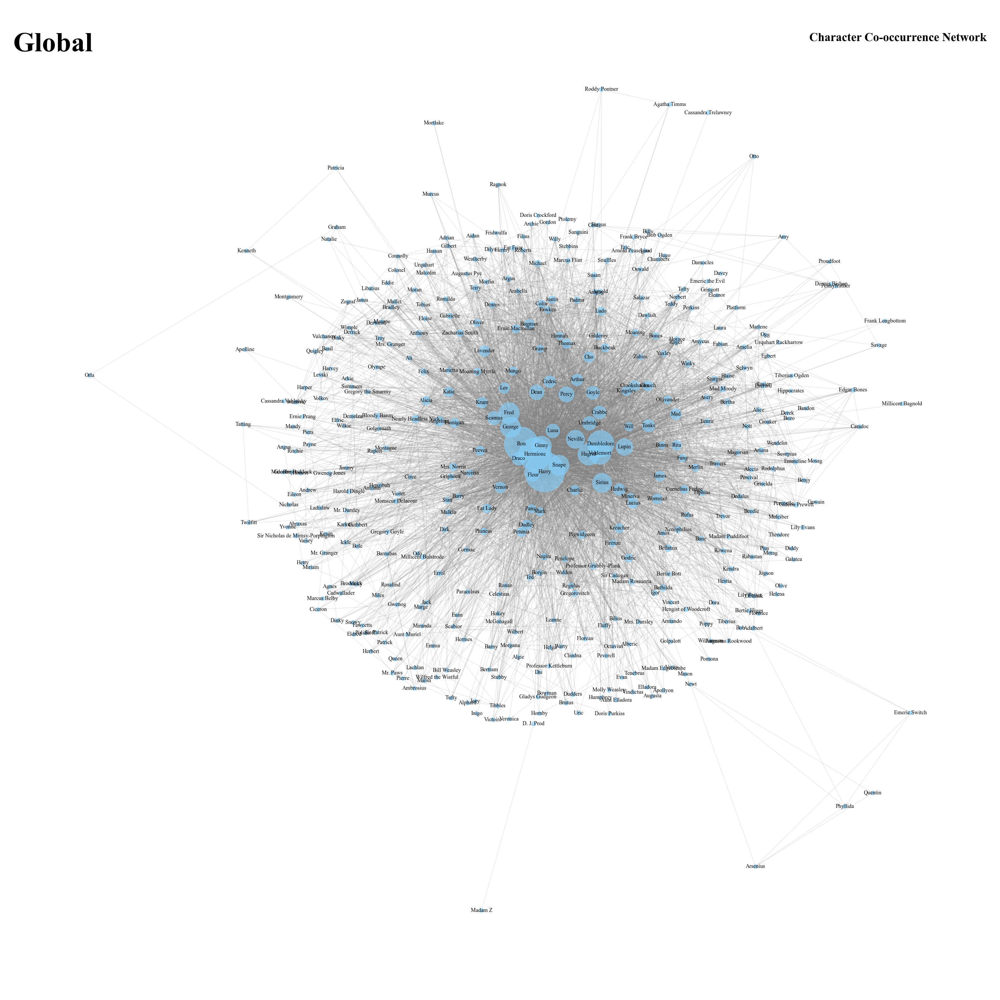

Grafo global generado en: character_network_global.png


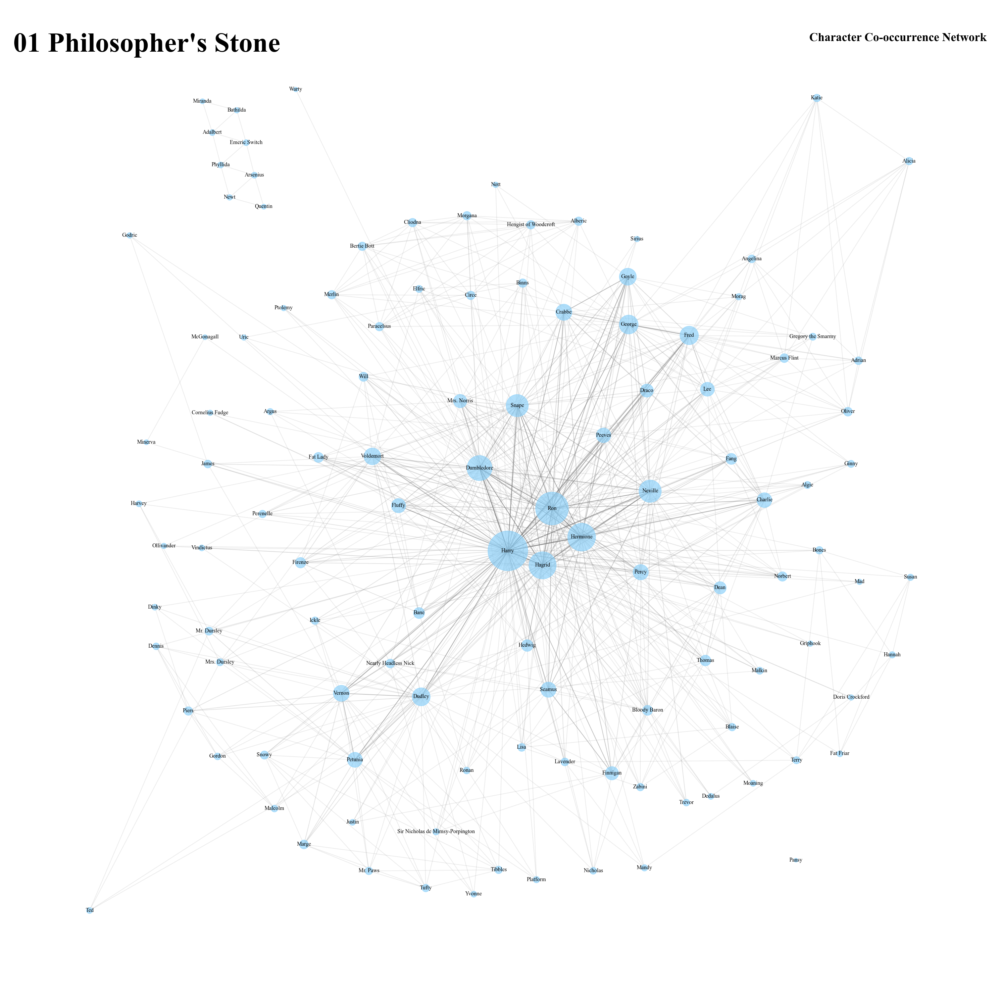

Libro 1 generado en: character_network_book_1.png


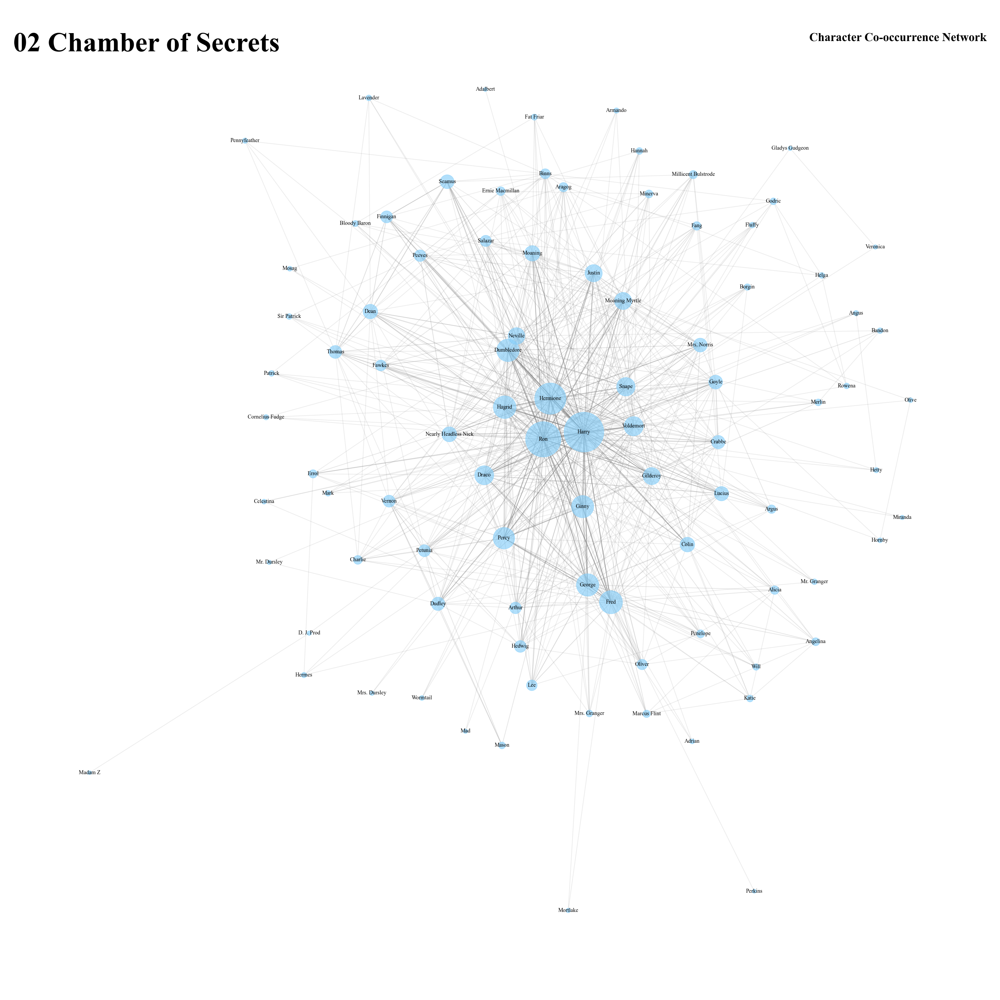

Libro 2 generado en: character_network_book_2.png


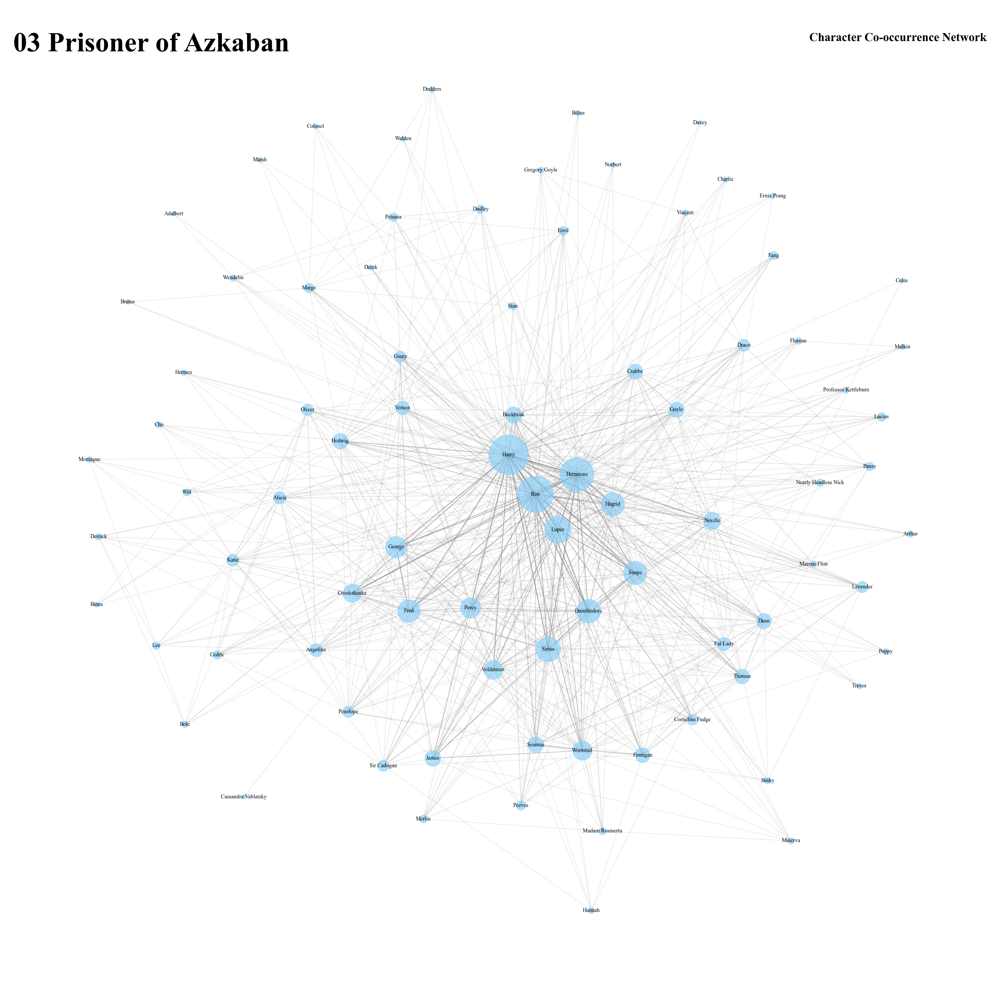

Libro 3 generado en: character_network_book_3.png


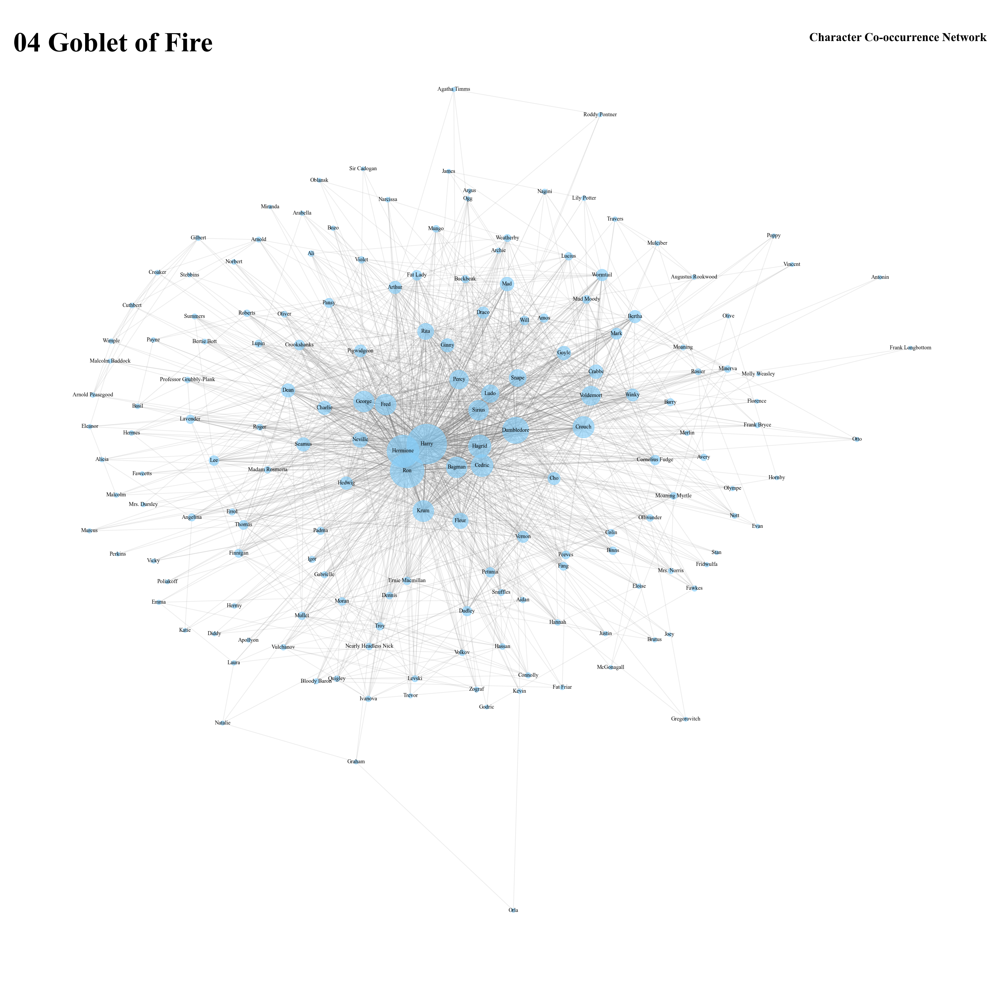

Libro 4 generado en: character_network_book_4.png


/opt/anaconda3/lib/python3.12/site-packages/pygraphviz/agraph.py:1403: RuntimeWarning: Warning: some nodes with margin (3.20,3.20) touch - falling back to straight line edges

  warnings.warn(b"".join(errors).decode(self.encoding), RuntimeWarning)


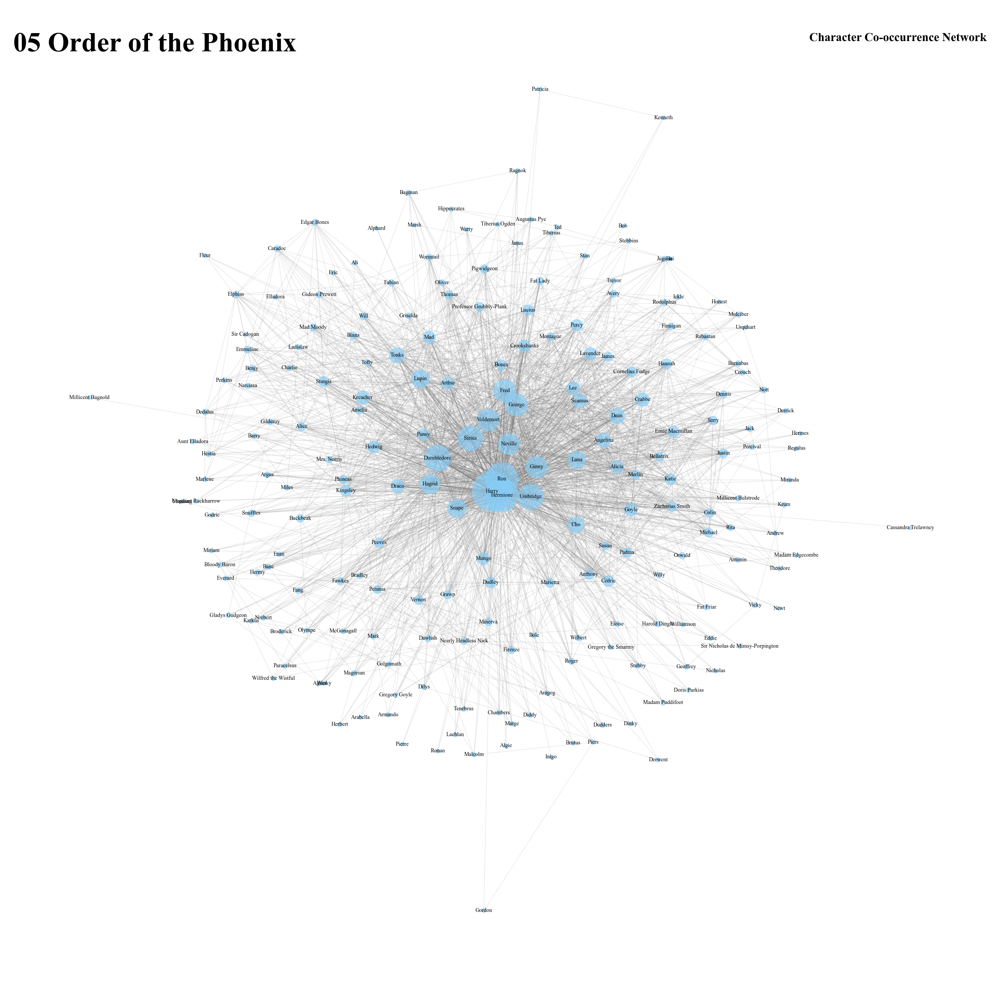

Libro 5 generado en: character_network_book_5.png


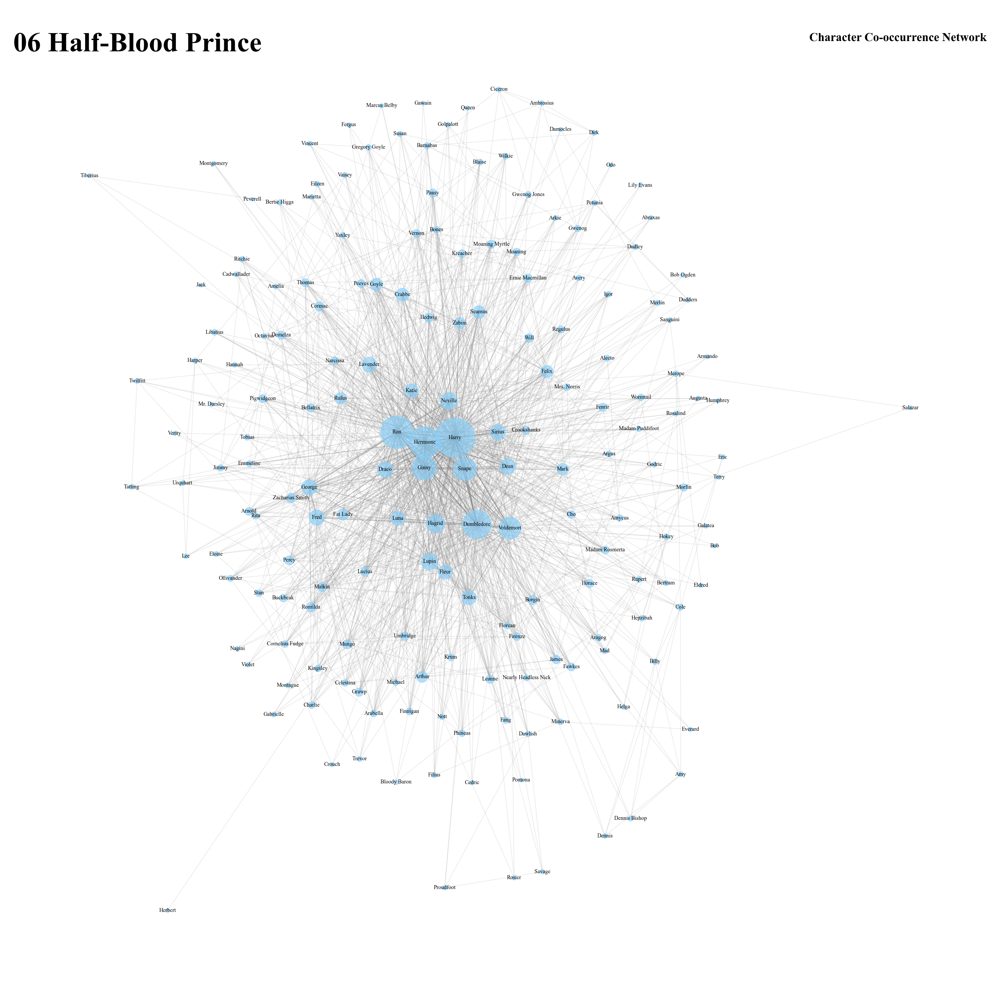

Libro 6 generado en: character_network_book_6.png


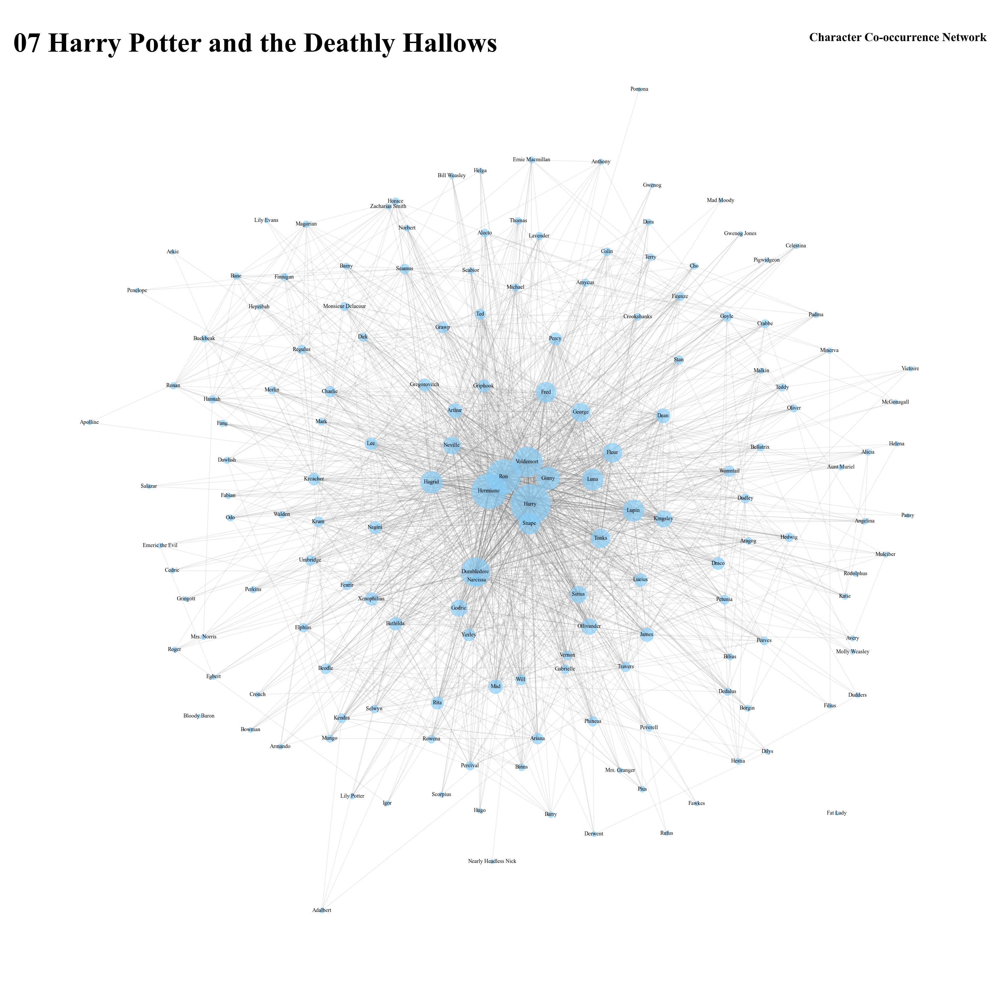

Libro 7 generado en: character_network_book_7.png


In [112]:
# Visualizar libros 1 al 7
visualizer = GraphVisualizer()

# Visualizar grafo global
G_global = graph_gen.get_global_graph()
path_global = visualizer.visualize(G_global, output_prefix="../results/figures/character_network", use_graphviz=True, book_id=None)
print(f"Grafo global generado en: {path_global}")

for BOOK_ID in range(1, 7 + 1):
    G = graph_gen.get_graph(BOOK_ID)
    path = visualizer.visualize(G, output_prefix="../results/figures/character_network", use_graphviz=True, book_id=BOOK_ID)
    print(f"Libro {BOOK_ID} generado en: {path}")



In [114]:
G = graph_gen.get_global_graph()

In [116]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import math
import seaborn as sns

class NetworkAnalysis:

    # ------------------------------------------------------------------
    # BASIC INFO
    # ------------------------------------------------------------------
    @staticmethod
    def basic_info(G):
        return {
            "num_nodes": G.number_of_nodes(),
            "num_edges": G.number_of_edges(),
        }

    # ------------------------------------------------------------------
    # DEGREE DISTRIBUTION
    # ------------------------------------------------------------------
    @staticmethod
    def degree_distribution(G):
        degrees = np.array([deg for _, deg in G.degree()])
        unique_deg, counts = np.unique(degrees, return_counts=True)
        pmf = counts / counts.sum()
        sorted_deg = np.sort(degrees)
        ccdf = 1.0 - np.arange(1, len(sorted_deg) + 1) / len(sorted_deg)

        return {
            "degrees": degrees,
            "unique_deg": unique_deg,
            "pmf": pmf,
            "sorted_deg": sorted_deg,
            "ccdf": ccdf,
            "average_degree": degrees.mean(),
            "max_degree": degrees.max(),
            "min_degree": degrees.min(),
        }

    # ------------------------------------------------------------------
    # CLUSTERING
    # ------------------------------------------------------------------
    @staticmethod
    def clustering_metrics(G):
        avg_clust = nx.average_clustering(G)
        local_clust = nx.clustering(G)
        return {
            "average_clustering": avg_clust,
            "local_clustering": local_clust,
        }

    # ------------------------------------------------------------------
    # PATH LENGTH & DIAMETER
    # ------------------------------------------------------------------
    @staticmethod
    def path_metrics(G):
        if nx.is_connected(G):
            avg_path = nx.average_shortest_path_length(G)
            diameter = nx.diameter(G)
        else:
            giant = max(nx.connected_components(G), key=len)
            sg = G.subgraph(giant)
            avg_path = nx.average_shortest_path_length(sg)
            diameter = nx.diameter(sg)

        return {
            "average_path_length": avg_path,
            "diameter": diameter,
        }

    # ------------------------------------------------------------------
    # DENSITY
    # ------------------------------------------------------------------
    @staticmethod
    def density(G):
        return nx.density(G)

    # ------------------------------------------------------------------
    # CENTRALITY
    # ------------------------------------------------------------------
    @staticmethod
    def centralities(G):
        return {
            "degree_centrality": nx.degree_centrality(G),
            "betweenness_centrality": nx.betweenness_centrality(G),
            "closeness_centrality": nx.closeness_centrality(G),
        }

    # ------------------------------------------------------------------
    # SMALL-WORLD PROPERTY
    # ------------------------------------------------------------------
    @staticmethod
    def small_world_property(N, avg_deg, observed_avg_path):
        if avg_deg <= 1:
            return False  # can't take log or too sparse
        expected_d = math.log(N) / math.log(avg_deg)
        rel_error = abs(observed_avg_path - expected_d) / expected_d
        return rel_error < 0.30

    # ------------------------------------------------------------------
    # GLOBAL + PER-NODE METRICS
    # ------------------------------------------------------------------
    @staticmethod
    def compute_all(G):
        basic = NetworkAnalysis.basic_info(G)
        dist = NetworkAnalysis.degree_distribution(G)
        clust = NetworkAnalysis.clustering_metrics(G)
        paths = NetworkAnalysis.path_metrics(G)
        central = NetworkAnalysis.centralities(G)

        is_conn = nx.is_connected(G)
        largest_comp = len(max(nx.connected_components(G), key=len))
        assortativity = nx.degree_assortativity_coefficient(G)

        N = basic["num_nodes"]
        avg_deg = dist["average_degree"]
        avg_path = paths["average_path_length"]

        small_world = NetworkAnalysis.small_world_property(N, avg_deg, avg_path)

        global_metrics = {
            "num_nodes": N,
            "num_edges": basic["num_edges"],
            "average_degree": avg_deg,
            "max_degree": dist["max_degree"],
            "min_degree": dist["min_degree"],
            "average_clustering": clust["average_clustering"],
            "density": NetworkAnalysis.density(G),
            "average_path_length": avg_path,
            "diameter": paths["diameter"],
            "is_connected": is_conn,
            "largest_component_size": largest_comp,
            "degree_assortativity": assortativity,
            "small_world_property": small_world,
        }

        global_df = pd.DataFrame([global_metrics])

        node_list = list(G.nodes())
        per_node_df = pd.DataFrame({
            "node": node_list,
            "degree": [G.degree(n) for n in node_list],
            "local_clustering": [clust["local_clustering"][n] for n in node_list],
            "degree_centrality": [central["degree_centrality"][n] for n in node_list],
            "betweenness_centrality": [central["betweenness_centrality"][n] for n in node_list],
            "closeness_centrality": [central["closeness_centrality"][n] for n in node_list],
        })

        return global_df, per_node_df

    # ------------------------------------------------------------------
    # DEGREE DISTRIBUTION PLOTS
    # ------------------------------------------------------------------
    @staticmethod
    def generate_degree_distribution(G):
        sns.set(style="whitegrid", context="talk", palette="pastel")
    
        dist = NetworkAnalysis.degree_distribution(G)
        degrees = dist["degrees"]
        unique_deg = dist["unique_deg"]
        pmf = dist["pmf"]
        sorted_deg = dist["sorted_deg"]
        ccdf = dist["ccdf"]
    
        fig = plt.figure(figsize=(14, 10))
        bins = np.arange(min(degrees)-0.5, max(degrees)+1.5, 1)

        ax_hist = plt.subplot2grid((2, 2), (0, 0), colspan=2)
        sns.histplot(degrees, bins=bins, kde=False, color="royalblue", alpha=0.8, ax=ax_hist)
        ax_hist.set_xlabel("Degree")
        ax_hist.set_ylabel("Count")
        ax_hist.set_title("Degree Histogram")
        ax_hist.grid(True, ls="--", lw=0.5)

        ax_pmf = plt.subplot2grid((2, 2), (1, 0))
        sns.scatterplot(x=unique_deg, y=pmf, s=50, color="steelblue", alpha=0.8, ax=ax_pmf)
        ax_pmf.set_xscale("log")
        ax_pmf.set_yscale("log")
        ax_pmf.set_xlabel("Degree (k)")
        ax_pmf.set_ylabel("P(k)")
        ax_pmf.set_title("PMF of Degree Distribution")
        ax_pmf.grid(True, which="both", ls="--", lw=0.5)

        ax_ccdf = plt.subplot2grid((2, 2), (1, 1))
        sns.scatterplot(x=sorted_deg, y=ccdf, s=50, color="tomato", alpha=0.8, ax=ax_ccdf)
        ax_ccdf.set_xscale("log")
        ax_ccdf.set_yscale("log")
        ax_ccdf.set_xlabel("Degree (k)")
        ax_ccdf.set_ylabel("P(K > k)")
        ax_ccdf.set_title("CCDF of Degree Distribution")
        ax_ccdf.grid(True, which="both", ls="--", lw=0.5)

        plt.suptitle("Degree Distribution of the Network", fontsize=18, weight="bold")
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

In [118]:
# Lista para almacenar resultados globales
global_metrics_list = []

# Lista para almacenar los dfs por personajes de los libros
book_node_dfs = []

# Obtener todos los grafos de libros
all_graphs = graph_gen.get_all_graphs()

# Recorrer cada libro
for i, (book_id, G_book) in enumerate(all_graphs.items(), start=1):
    global_df, per_node_df = NetworkAnalysis.compute_all(G_book)
    
    # Añadir columna indicando el libro
    global_df["graph_id"] = i  # índice del libro empezando en 1
    
    global_metrics_list.append(global_df)
    book_node_dfs.append(per_node_df)

# Procesar el grafo global
G_global = graph_gen.get_global_graph()
global_df, per_node_df = NetworkAnalysis.compute_all(G_global)
global_df["graph_id"] = "global"  # marcar como global

global_metrics_list.append(global_df)

# Guardar el df global de todos los grafos
df_global_all = pd.concat(global_metrics_list, ignore_index=True)

# Lista de dfs por personajes (solo libros)
dfs_by_book = book_node_dfs

# df de personajes global
df_global_characters = per_node_df

In [119]:
df_global_all

,num_nodes,num_edges,average_degree,max_degree,min_degree,average_clustering,density,average_path_length,diameter,is_connected,largest_component_size,degree_assortativity,small_world_property,graph_id
0,116,661,11.396552,101,0,0.781533,0.099100,1.940575,4,False,107,-0.263872,True,1
1,92,651,14.152174,85,1,0.767109,0.155518,1.911132,4,True,92,-0.365348,True,2
2,84,702,16.714286,80,1,0.780010,0.201377,1.810671,3,True,84,-0.355358,True,3
3,172,1538,17.883721,159,2,0.796033,0.104583,1.957636,4,True,172,-0.348201,True,4
4,218,2221,20.376147,205,1,0.787828,0.093899,1.947406,4,True,218,-0.352560,True,5
5,185,1458,15.762162,170,1,0.773553,0.085664,1.974971,4,True,185,-0.369701,True,6
6,164,1689,20.597561,152,0,0.763737,0.126365,1.895637,3,False,162,-0.351138,True,7
7,440,5444,24.745455,408,1,0.787431,0.056368,2.016204,4,True,440,-0.328135,True,global


In [1454]:
global_df, per_node_df = NetworkAnalysis.compute_all(G)

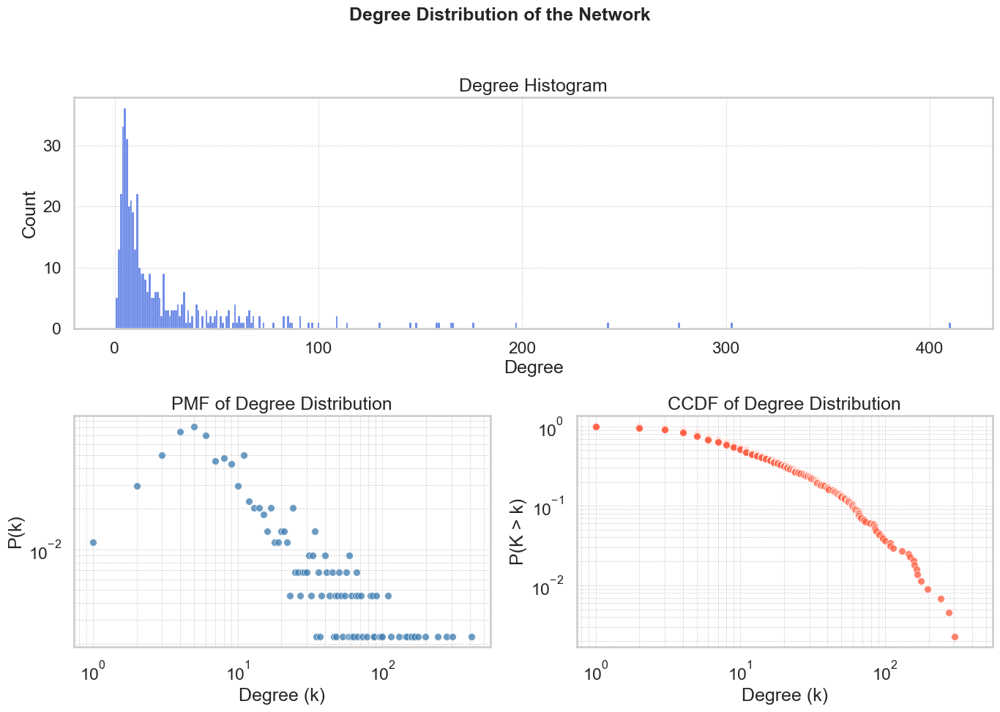

In [1496]:
NetworkAnalysis.generate_degree_distribution(G)

In [1420]:
global_df

,num_nodes,num_edges,average_degree,max_degree,min_degree,average_clustering,density,average_path_length,diameter,is_connected,largest_component_size,degree_assortativity,small_world_property
0,440,3313,15.059091,307,0,0.645229,0.034303,2.30814,6,False,410,-0.295129,True


In [1162]:
per_node_df

,node,degree,local_clustering,degree_centrality,betweenness_centrality,closeness_centrality
0,Harry,322,0.058706,0.759434,0.408071,0.803030
1,Harvey,1,0.000000,0.002358,0.000000,0.445846
2,Dumbledore,192,0.125164,0.452830,0.084057,0.634731
3,Voldemort,111,0.233743,0.261792,0.018154,0.561589
4,Godric,26,0.523077,0.061321,0.005172,0.480726
...,...,...,...,...,...,...
420,Walden,11,1.000000,0.025943,0.000000,0.465934
421,Molly Weasley,4,1.000000,0.009434,0.000000,0.448203
422,Scorpius,1,0.000000,0.002358,0.000000,0.397749
423,Victoire,2,1.000000,0.004717,0.000000,0.320242


In [122]:
import networkx as nx
import math
import numpy as np
from networkx.algorithms.community import greedy_modularity_communities

class ModelGenerator:
    def __init__(self, G, main_char_percent=0.05, core_percent=0.1):
        self.G = G
        self.N = G.number_of_nodes()
        self.E = G.number_of_edges()
        self.main_char_percent = main_char_percent
        self.core_percent = core_percent

    # ---------------- ER ----------------
    def erdos_renyi(self):
        if self.N < 2:
            return nx.empty_graph(self.N)
        p = self.E / (self.N * (self.N - 1) / 2)
        return nx.erdos_renyi_graph(self.N, p)

    # ---------------- BA ----------------
    def barabasi_albert(self):
        if self.N < 2:
            return nx.empty_graph(self.N)
        m = max(1, math.floor(self.E / self.N))
        num_main = max(1, int(self.N * self.main_char_percent))
        degree_sorted = sorted(self.G.degree(), key=lambda x: x[1], reverse=True)
        main_nodes = [node for node, _ in degree_sorted[:num_main]]
        if len(main_nodes) == 1:
            init_graph = nx.path_graph(2)
        else:
            init_graph = nx.Graph()
            init_graph.add_nodes_from(range(len(main_nodes)))
            for i in range(len(main_nodes)-1):
                init_graph.add_edge(i, i+1)
        return nx.barabasi_albert_graph(self.N, m, initial_graph=init_graph)

    # ---------------- WS ----------------
    def watts_strogatz(self):
        if self.N < 3:
            return nx.empty_graph(self.N)
        avg_degree = 2 * self.E / self.N if self.N > 0 else 0
        k = max(2, int(2 * math.floor(avg_degree / 2)))
        if k >= self.N:
            k = max(2, self.N - 1 - (self.N % 2))
        clustering = nx.average_clustering(self.G)
        p = max(0.01, min(0.9, 1 - clustering))
        return nx.watts_strogatz_graph(self.N, k, p)

    # ---------------- Core–Periphery ----------------
    def core_periphery(self):
        if self.N < 2:
            return nx.empty_graph(self.N)
        nodes = list(self.G.nodes())
        num_core = max(2, int(self.N * self.core_percent))
        degree_sorted = sorted(self.G.degree(), key=lambda x: x[1], reverse=True)
        core_nodes = [node for node, _ in degree_sorted[:num_core]]
        periphery_nodes = [node for node in nodes if node not in core_nodes]

        # Core density
        G_core = self.G.subgraph(core_nodes)
        E_core = G_core.number_of_edges()
        max_core_edges = num_core * (num_core - 1) / 2
        p_core = E_core / max_core_edges if max_core_edges > 0 else 0.5

        # Core–periphery density
        edges_cp = sum(1 for u, v in self.G.edges()
                       if (u in core_nodes and v in periphery_nodes) or
                          (v in core_nodes and u in periphery_nodes))
        p_cp = edges_cp / (num_core * len(periphery_nodes)) if len(periphery_nodes) > 0 else 0.1

        # Periphery–periphery density
        G_periphery = self.G.subgraph(periphery_nodes)
        E_pp = G_periphery.number_of_edges()
        max_pp_edges = len(periphery_nodes) * (len(periphery_nodes) - 1) / 2
        p_pp = E_pp / max_pp_edges if max_pp_edges > 0 else 0.01

        H = nx.Graph()
        H.add_nodes_from(nodes)

        # Core–core edges
        for i, u in enumerate(core_nodes):
            for v in core_nodes[i+1:]:
                if np.random.random() < p_core:
                    H.add_edge(u, v)

        # Core–periphery edges
        for u in core_nodes:
            for v in periphery_nodes:
                if np.random.random() < p_cp:
                    H.add_edge(u, v)

        # Periphery–periphery edges
        for i, u in enumerate(periphery_nodes):
            for v in periphery_nodes[i+1:]:
                if np.random.random() < p_pp:
                    H.add_edge(u, v)

        return H

    # ---------------- SBM ----------------
    def stochastic_block_model(self):
        if self.N < 2:
            return nx.empty_graph(self.N)

        # Detect communities using modularity
        communities = list(greedy_modularity_communities(self.G))
        sizes = [len(c) for c in communities]
        nodes_list = [list(c) for c in communities]
        node_idx_map = {node: i for i, node in enumerate(self.G.nodes())}

        # Initialize block probability matrix
        k = len(sizes)
        p_matrix = np.zeros((k, k))

        # Compute intra- and inter-block probabilities
        for i in range(k):
            for j in range(k):
                if i == j:
                    # intra-block
                    subgraph = self.G.subgraph(nodes_list[i])
                    max_edges = sizes[i]*(sizes[i]-1)/2
                    p_matrix[i, j] = subgraph.number_of_edges()/max_edges if max_edges>0 else 0.1
                else:
                    # inter-block
                    edges_ij = sum(1 for u, v in self.G.edges()
                                   if (u in nodes_list[i] and v in nodes_list[j]) or
                                      (v in nodes_list[i] and u in nodes_list[j]))
                    p_matrix[i, j] = edges_ij / (sizes[i]*sizes[j]) if sizes[i]*sizes[j]>0 else 0.01

        # Generate SBM
        sbm = nx.stochastic_block_model(sizes, p_matrix, nodelist=list(self.G.nodes()))
        return sbm

    # ---------------- Generate All Models ----------------
    def generate_models(self):
        return {
            "erdos_renyi": self.erdos_renyi(),
            "barabasi_albert": self.barabasi_albert(),
            "watts_strogatz": self.watts_strogatz(),
            "core_periphery": self.core_periphery(),
            "stochastic_block_model": self.stochastic_block_model()
        }


In [124]:
# List to store global metrics
global_metrics_list = []

# List to store per-node dfs
node_dfs = []

# Dictionary of models
models_dict = {
    "erdos_renyi": G_er,
    "barabasi_albert": G_ba,
    "watts_strogatz": G_ws,
    "core_periphery": G_cp,
    "stochastic_block_model": G_sb
}

# Process each model
for name, G_model in models_dict.items():
    global_df, per_node_df = NetworkAnalysis.compute_all(G_model)
    global_df["graph_name"] = name
    global_metrics_list.append(global_df)
    node_dfs.append(per_node_df)

# Add the global graph
G_global = graph_gen.get_global_graph()
global_df, per_node_df = NetworkAnalysis.compute_all(G_global)
global_df["graph_name"] = "global"
global_metrics_list.append(global_df)

# Concatenate all global metrics into one DataFrame
df_global_all = pd.concat(global_metrics_list, ignore_index=True)

# Separate list of per-node DataFrames (models only)
dfs_by_model = node_dfs

# Global node DataFrame
df_global_characters = per_node_df

NameError: name 'G_er' is not defined

In [1185]:
df_global_all

,num_nodes,num_edges,average_degree,max_degree,min_degree,average_clustering,density,average_path_length,diameter,is_connected,largest_component_size,degree_assortativity,small_world_property,graph_name
0,425,3633,17.096471,29,6,0.040768,0.040322,2.442630,4,True,425,0.011094,True,erdos_renyi
1,425,3252,15.303529,99,4,0.080860,0.036093,2.456104,4,True,425,-0.063706,True,barabasi_albert
2,425,3400,16.000000,23,11,0.236830,0.037736,2.636537,4,True,425,-0.053464,True,watts_strogatz
3,425,3695,17.388235,98,3,0.269105,0.041010,2.305094,4,True,425,-0.200283,True,core_periphery
4,425,3671,17.275294,35,1,0.084534,0.040744,2.516615,6,True,425,0.188042,True,stochastic_block_model
5,425,3627,17.068235,322,1,0.675982,0.040255,2.288968,5,True,425,-0.272099,True,global


In [1498]:
def simulate_robustness(G, attack_type='random', protect_fraction=0.0):

    G = G.copy()
    num_nodes = G.number_of_nodes()
    removed = 0

    if protect_fraction > 0:
        k = int(protect_fraction * num_nodes)
        if k > 0:
            protected_nodes = set(
                sorted(G.nodes(), key=lambda x: G.degree(x), reverse=True)[:k]
            )
        else:
            protected_nodes = set()
    else:
        protected_nodes = set()

    if attack_type == "random":
        removal_order = list(G.nodes())
        random.shuffle(removal_order)
    elif attack_type == "targeted":
        removal_order = sorted(G.nodes(), key=lambda x: G.degree(x), reverse=True)

    results = []

    for node in removal_order:

        if node in protected_nodes:
            continue
        G.remove_node(node)
        removed += 1

        if G.number_of_nodes() > 0:
            giant_cc_size = len(max(nx.connected_components(G), key=len))
        else:
            giant_cc_size = 0

        fraction_removed = removed / num_nodes
        gc_fraction = giant_cc_size / num_nodes

        results.append((fraction_removed, gc_fraction))

    return results 

In [1108]:
import random

In [1110]:
rand_res = simulate_robustness(G, attack_type='random')
frac_r, gc_r = zip(*rand_res)

targ_res = simulate_robustness(G, attack_type='targeted')
frac_t, gc_t = zip(*targ_res)

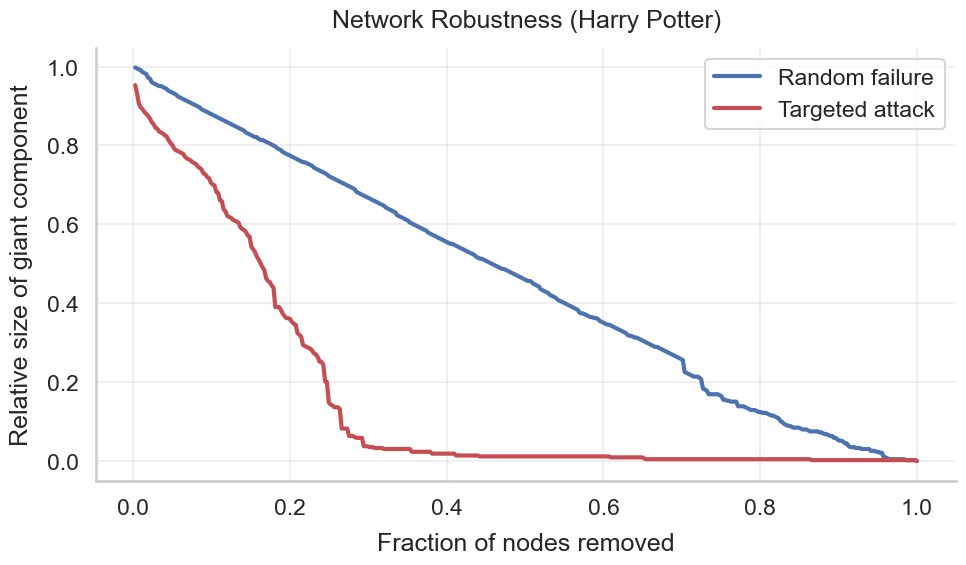

In [1500]:
import matplotlib.pyplot as plt
import seaborn as sns

# Apply a clean seaborn theme
sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(10, 6))

# Use seaborn color palette
palette = sns.color_palette("deep")

plt.plot(frac_r, gc_r, label="Random failure", linewidth=3, color=palette[0])
plt.plot(frac_t, gc_t, label="Targeted attack", linewidth=3, color=palette[3])

plt.xlabel("Fraction of nodes removed", labelpad=10)
plt.ylabel("Relative size of giant component", labelpad=10)
plt.title("Network Robustness (Harry Potter)", pad=15)

plt.legend(frameon=True)
plt.grid(True, alpha=0.3)

# Remove top and right spines for a cleaner look
sns.despine()

plt.tight_layout()
plt.show()

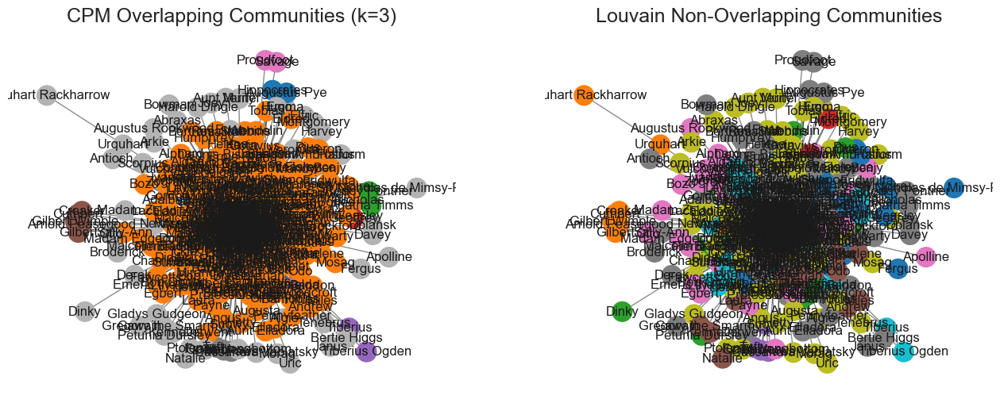

In [1201]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import community as community_louvain  # pip install python-louvain

# ---------- CPM (overlapping communities) ----------
def cpm(G, k):
    cliques = [c for c in nx.find_cliques(G) if len(c) >= k]
    clique_graph = nx.Graph()
    for i, c1 in enumerate(cliques):
        clique_graph.add_node(i, members=c1)
        for j, c2 in enumerate(cliques):
            if i < j and len(set(c1) & set(c2)) >= k - 1:
                clique_graph.add_edge(i, j)
    communities = []
    for component in nx.connected_components(clique_graph):
        community_nodes = set()
        for idx in component:
            community_nodes.update(clique_graph.nodes[idx]['members'])
        communities.append(community_nodes)
    return communities

k = 3
overlapping_communities = cpm(G, k)

# ---------- Louvain Method (non-overlapping) ----------
partition = community_louvain.best_partition(G)  # returns {node: community_id}

# ---------- Visualization ----------
pos = nx.spring_layout(G, seed=42)
colors = list(mcolors.TABLEAU_COLORS.values())

# CPM node colors
node_colors_cpm = {node: [] for node in G.nodes()}
for i, community in enumerate(overlapping_communities):
    color = colors[i % len(colors)]
    for node in community:
        node_colors_cpm[node].append(color)

def blend_colors(color_list):
    if not color_list:
        return (0.7, 0.7, 0.7, 1)  # light gray for nodes not in any CPM community
    if len(color_list) == 1:
        return color_list[0]
    rgba = [mcolors.to_rgba(c) for c in color_list]
    avg = tuple(sum(x)/len(x) for x in zip(*rgba))
    return avg

node_color_final_cpm = [blend_colors(node_colors_cpm[node]) for node in G.nodes()]
node_color_louvain = [colors[partition[node] % len(colors)] for node in G.nodes()]

# --- Plot both ---
plt.figure(figsize=(40, 40))

# CPM
plt.subplot(1, 2, 1)
nx.draw_networkx_edges(G, pos, alpha=0.5)
nx.draw_networkx_nodes(G, pos, node_color=node_color_final_cpm, node_size=300)
nx.draw_networkx_labels(G, pos)
plt.title(f"CPM Overlapping Communities (k={k})")
plt.axis('off')

# Louvain
plt.subplot(1, 2, 2)
nx.draw_networkx_edges(G, pos, alpha=0.5)
nx.draw_networkx_nodes(G, pos, node_color=node_color_louvain, node_size=300)
nx.draw_networkx_labels(G, pos)
plt.title("Louvain Non-Overlapping Communities")
plt.axis('off')

plt.show()

In [1212]:
import cdlib.algorithms as algs
print([f for f in dir(algs) if not f.startswith('_')])

['CPM_Bipartite', 'agdl', 'angel', 'aslpaw', 'async_fluid', 'attribute_clustering', 'bayan', 'belief', 'bimlpa', 'bipartite_clustering', 'coach', 'condor', 'conga', 'congo', 'core_expansion', 'cpm', 'crisp_partition', 'dcs', 'demon', 'der', 'dpclus', 'ebgc', 'edge_clustering', 'ego_networks', 'eigenvector', 'em', 'endntm', 'eva', 'frc_fgsn', 'ga', 'gdmp2', 'girvan_newman', 'graph_entropy', 'greedy_modularity', 'head_tail', 'hierarchical_link_community', 'ilouvain', 'infomap', 'infomap_bipartite', 'internal', 'internal_dcd', 'ipca', 'kclique', 'kcut', 'label_propagation', 'lais2', 'leiden', 'lemon', 'lfm', 'louvain', 'lpam', 'lpanni', 'lswl', 'lswl_plus', 'markov_clustering', 'mcode', 'mod_m', 'mod_r', 'multicom', 'node_perception', 'overlapping_partition', 'overlapping_seed_set_expansion', 'paris', 'percomvc', 'principled_clustering', 'pycombo', 'r_spectral_clustering', 'rb_pots', 'rber_pots', 'ricci_community', 'sbm_dl', 'sbm_dl_nested', 'scan', 'siblinarity_antichain', 'significance_

In [1208]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from cdlib import algorithms, viz


# --- Run BigClam via cdlib ---
# dimensions = embedding size, iterations = how many gradient steps
communities = algorithms.big_clam(G, dimensions=8, iterations=100, learning_rate=0.005)
# communities is a NodeClustering object with .communities (list of sets)
print("Detected overlapping communities:", communities.communities)

# --- Prepare to visualize overlapping communities ---
pos = nx.spring_layout(G, seed=42)

# We'll color each community, and for nodes in multiple communities, blend colors
colors = list(mcolors.TABLEAU_COLORS.values())
node_colors = {node: [] for node in G.nodes()}

for i, comm in enumerate(communities.communities):
    color = colors[i % len(colors)]
    for node in comm:
        node_colors[node].append(color)

def blend_colors(color_list):
    if not color_list:
        return (0.7, 0.7, 0.7, 1)  # gray for nodes not in any community (unlikely in BigClam)
    if len(color_list) == 1:
        return color_list[0]
    rgba = [mcolors.to_rgba(c) for c in color_list]
    avg = tuple(sum(x) / len(x) for x in zip(*rgba))
    return avg

node_color_final = [blend_colors(node_colors[node]) for node in G.nodes()]

# --- Draw the graph ---
plt.figure(figsize=(8, 6))
nx.draw_networkx_edges(G, pos, alpha=0.5)
nx.draw_networkx_nodes(G, pos, node_size=300, node_color=node_color_final)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title("BigClam Overlapping Communities (cdlib)")
plt.axis("off")
plt.show()

Note: to be able to use all crisp methods, you need to install some additional packages:  {'bayanpy', 'leidenalg', 'infomap', 'graph_tool'}
Note: to be able to use all crisp methods, you need to install some additional packages:  {'ASLPAw', 'pyclustering'}
Note: to be able to use all crisp methods, you need to install some additional packages:  {'leidenalg', 'infomap'}


AttributeError: module 'cdlib.algorithms' has no attribute 'big_clam'

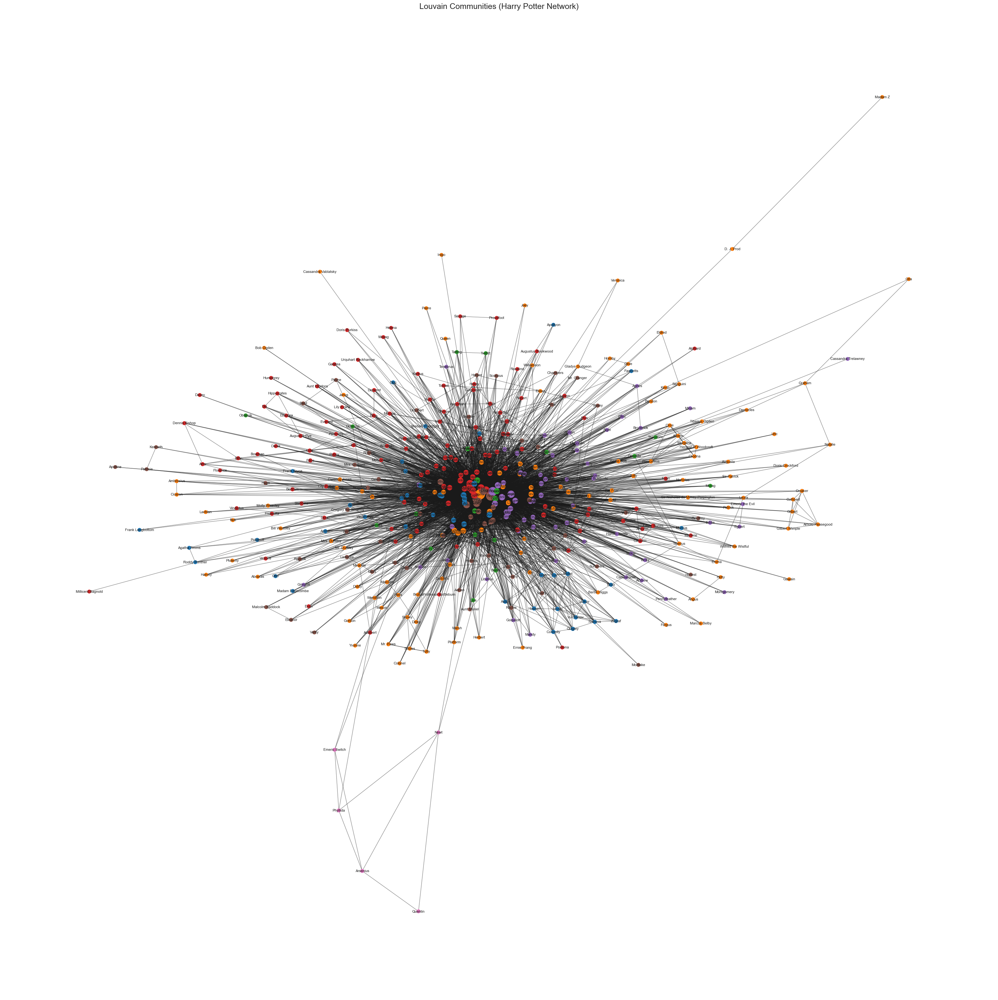

In [1502]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import community as community_louvain  # pip install python-louvain

# --- Example graph ---
# --- Louvain community detection ---
partition = community_louvain.best_partition(G)
# partition = {node: community_id}

# --- Prepare visualization ---
pos = nx.spring_layout(G, seed=42)
colors = list(mcolors.TABLEAU_COLORS.values())
node_color = [colors[partition[node] % len(colors)] for node in G.nodes()]

# Optional: scale node size by degree
node_size = [50 + G.degree(node) for node in G.nodes()]

# Optional: scale edge opacity by weight (if weighted)
edges = G.edges(data=True)
edge_alpha = [edge[2].get('weight', 1)*0.7 for edge in edges]

# --- Draw ---
plt.figure(figsize=(40, 40))
nx.draw_networkx_edges(G, pos, alpha=0.5)
nx.draw_networkx_nodes(G, pos, node_size=node_size, node_color=node_color)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title("Louvain Communities (Harry Potter Network)")
plt.axis("off")
plt.show()

In [1250]:
df['categories']

0      [Hufflepuff, Dumbledore’s Army]
1                         [Gryffindor]
2                          [Ravenclaw]
3                [Chocolate Frog Card]
4                              [Other]
                    ...               
682                            [Other]
683                 [Quidditch Player]
684                       [Hufflepuff]
685                 [Quidditch Player]
686                            [Other]
Name: categories, Length: 687, dtype: object

In [1504]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import ast

# --- Preparar data ---
# df: columnas 'node' y 'categories'
# partition: diccionario {node: community_id}

# Convertimos listas de categorías en la categoría "principal"
# (puedes cambiar la lógica si quieres otra estrategia)
# df['categories'] = df['categories'].apply(lambda x: ast.literal_eval(x) if x != '[]' else []
# Creamos listas alineadas para la matriz de confusión
data = []
for node in G.nodes():
    if node in df['name'].values:
        categories = df.loc[df['name']==node, 'categories'].values[0]
        community = partition[node]
        for cat in categories:
            data.append({'category': cat, 'community': community})

df_crosstab = pd.DataFrame(data)
df_crosstab['category'] = df_crosstab['category'].replace(CATEGORY_MAP)


# -------------------------
# CREATE CONFUSION-LIKE MATRIX
# -------------------------
conf_mat = pd.crosstab(df_crosstab['category'], df_crosstab['community'])



TypeError: 'float' object is not iterable

In [1298]:
df_crosstab

,category,community
0,Quidditch Player,0
1,Gryffindor,0
2,Slug Club,0
3,Related to the Blacks,0
4,Dumbledore’s Army,0
...,...,...
563,Related to the Blacks,1
564,Order of the Phoenix,1
565,Other,0
566,Other,8


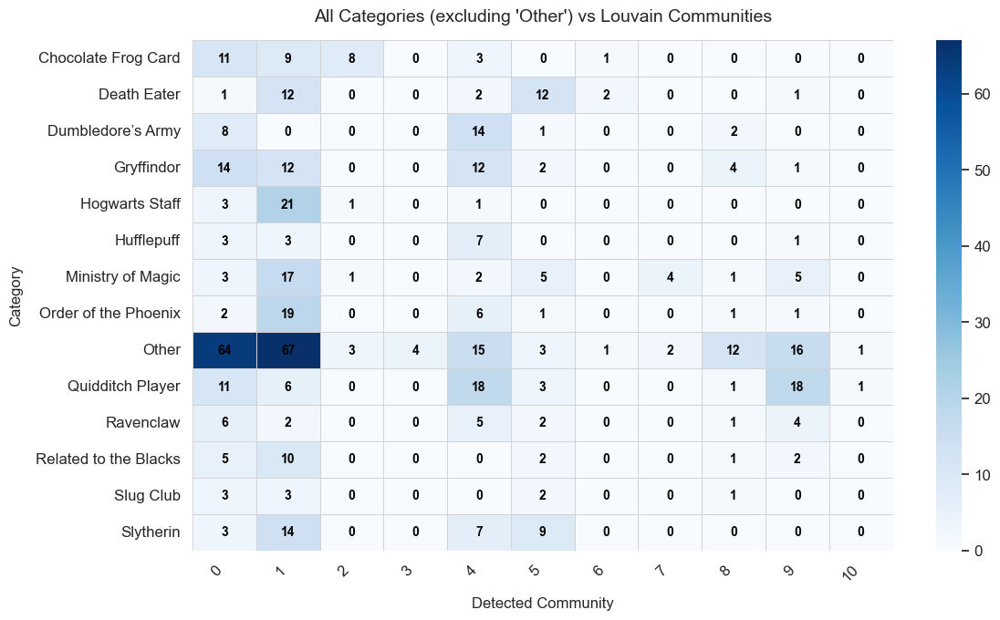

In [1506]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style
sns.set(style="whitegrid", font_scale=1.1)  # modern, clean font and spacing

plt.figure(figsize=(12,7))

# Modern heatmap
sns.heatmap(
    conf_mat, 
    annot=True, 
    fmt="d", 
    cmap="Blues",       # clean blue gradient
    cbar=True, 
    linewidths=0.5,     # subtle grid lines
    linecolor='lightgray',
    annot_kws={"size":10, "weight":'bold', "color":"black"}
)

# Remove top and right spines
sns.despine(left=True, bottom=True)

plt.ylabel("Category", fontsize=12, labelpad=10)
plt.xlabel("Detected Community", fontsize=12, labelpad=10)
plt.title("All Categories (excluding 'Other') vs Louvain Communities", fontsize=14, pad=15)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [1574]:
import pandas as pd
import networkx as nx
from tqdm import tqdm

def generate_incremental_graphs_sequential(df_links):
    """
    Generates incremental graphs per line and per chapter for only the first two books
    and a global network with sequential line indices across books.
    Stores both per-book and true global metrics correctly.
    """
    data_per_book = {}
    global_G = nx.Graph()
    global_lines = {}
    global_chapters = {}

    # Select only the first 2 books
    books = df_links['book'].unique()[:2]

    global_step = 0  # sequential line index across all books

    for book_id in books:
        df_book = df_links[df_links['book'] == book_id].sort_values('line_index')
        book_lines = {}
        book_chapters = {}
        G = nx.Graph()
        last_chapter = None

        for _, row in tqdm(df_book.iterrows(), total=len(df_book), desc=f"Processing Book {book_id}"):
            char1 = row['character1']
            char2 = row['character2']
            line_index = row['line_index']
            chapter = row['chapter']

            # --- Add nodes/edges per book ---
            if pd.isna(char2):
                G.add_node(char1)
            else:
                if G.has_edge(char1, char2):
                    G[char1][char2]['weight'] += 1
                else:
                    G.add_edge(char1, char2, weight=1)

            # --- Add nodes/edges to global graph ---
            if pd.isna(char2):
                global_G.add_node(char1)
            else:
                if global_G.has_edge(char1, char2):
                    global_G[char1][char2]['weight'] += 1
                else:
                    global_G.add_edge(char1, char2, weight=1)

            # --- Compute metrics ---
            metrics_book = NetworkAnalysis.compute_all(G)
            metrics_global = NetworkAnalysis.compute_all(global_G)

            # --- Store per-book metrics ---
            book_lines[line_index] = (G.copy(), metrics_book)

            # --- Store global metrics using true cumulative global_step ---
            global_lines[global_step] = (global_G.copy(), metrics_global)
            global_step += 1  # increment for next line

            # --- Per-chapter metrics ---
            if chapter != last_chapter:
                book_chapters[chapter] = (G.copy(), metrics_book)
                global_chapters[chapter] = (global_G.copy(), metrics_global)
                last_chapter = chapter

        data_per_book[book_id] = {"lines": book_lines, "chapters": book_chapters}

    global_data = {"lines": global_lines, "chapters": global_chapters}
    return data_per_book, global_data

In [1576]:
# Make sure df_links exists and is sorted by line_index
data_per_book, global_data = generate_incremental_graphs(df_links)

Processing Book 2:  36%|██████▊            | 3688/10284 [11:00<19:41,  5.58it/s]

KeyboardInterrupt



In [1570]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_network_metrics(data_per_book, global_data):
    sns.set(style="whitegrid", context="talk", palette="pastel")

    # --------------------------
    # Prepare per-book metrics in sequential order
    # --------------------------
    df_books_seq = []
    line_offset = 0
    for book_id, data in sorted(data_per_book.items()):
        for step, (G, metrics_tuple) in sorted(data["lines"].items()):
            global_metrics = metrics_tuple[0].iloc[0].to_dict()  # per-book global_df
            global_metrics["book"] = f"Book {book_id}"
            global_metrics["step"] = step + line_offset
            df_books_seq.append(global_metrics)
        max_step = max(data["lines"].keys())
        line_offset += max_step + 1

    df_books_seq = pd.DataFrame(df_books_seq)

    # --------------------------
    # Prepare true global metrics
    # --------------------------
    df_global_seq = []
    for step, (G, metrics_tuple) in sorted(global_data["lines"].items()):
        global_metrics = metrics_tuple[0].iloc[0].to_dict()  # true cumulative global metrics
        global_metrics["book"] = "Global"
        global_metrics["step"] = step
        df_global_seq.append(global_metrics)
    df_global_seq = pd.DataFrame(df_global_seq)

    # --------------------------
    # Plot Evolution of Global Metrics
    # --------------------------
    metrics_to_plot = [
        "num_nodes", "num_edges", "average_degree",
        "average_clustering", "density", "average_path_length", "diameter"
    ]

    fig, axes = plt.subplots(len(metrics_to_plot), 1, figsize=(16, 5*len(metrics_to_plot)), sharex=True)

    for i, metric in enumerate(metrics_to_plot):
        ax = axes[i]
        sns.lineplot(data=df_books_seq, x="step", y=metric, hue="book", ax=ax)
        # Plot true global cumulative metrics
        ax.plot(df_global_seq["step"], df_global_seq[metric], color="black", linestyle="--", label="Global")
        ax.set_title(f"Evolution of {metric}")
        ax.set_xlabel("Line Index (sequential across books)")
        ax.set_ylabel(metric)
        ax.legend()

    plt.tight_layout()
    plt.show()

    # --------------------------
    # Prepare per-character metrics
    # --------------------------
    per_node_records = []

    # Per-book per-character
    line_offset = 0
    for book_id, data in sorted(data_per_book.items()):
        for step, (G, metrics_tuple) in sorted(data["lines"].items()):
            per_node = metrics_tuple[1].copy()  # per_node_df
            per_node["step"] = step + line_offset
            per_node["book"] = f"Book {book_id}"
            per_node_records.append(per_node)
        max_step = max(data["lines"].keys())
        line_offset += max_step + 1

    # Global per-character
    for step, (G, metrics_tuple) in sorted(global_data["lines"].items()):
        per_node = metrics_tuple[1].copy()
        per_node["step"] = step
        per_node["book"] = "Global"
        per_node_records.append(per_node)

    df_nodes_seq = pd.concat(per_node_records, ignore_index=True)

    # --------------------------
    # Plot per-character metrics
    # --------------------------
    per_node_metrics = ["degree", "degree_centrality", "betweenness_centrality", "closeness_centrality"]
    fig, axes = plt.subplots(len(per_node_metrics), 1, figsize=(16, 5*len(per_node_metrics)), sharex=True)

    for i, metric in enumerate(per_node_metrics):
        ax = axes[i]
        sns.lineplot(data=df_nodes_seq, x="step", y=metric, hue="node", legend=False, ax=ax)
        ax.set_title(f"Per-character {metric} evolution")
        ax.set_xlabel("Line Index (sequential across books)")
        ax.set_ylabel(metric)

    plt.tight_layout()
    plt.show()

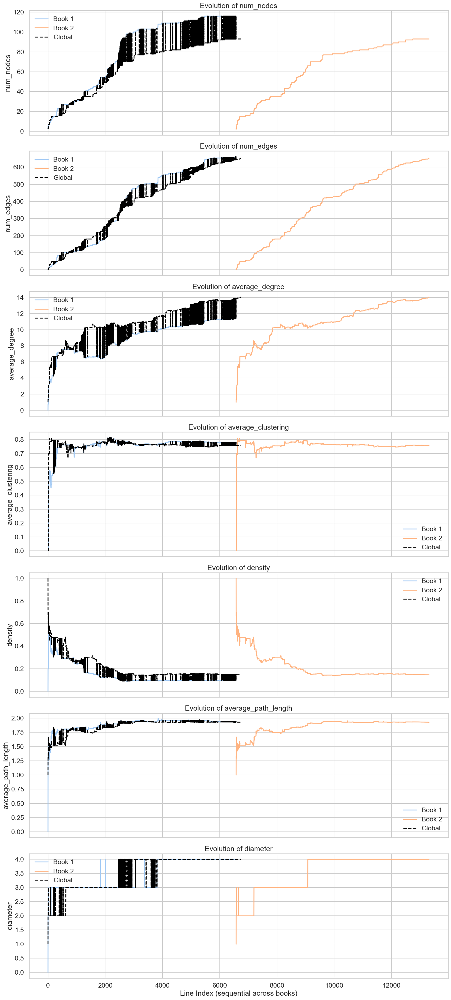


KeyboardInterrupt


KeyboardInterrupt



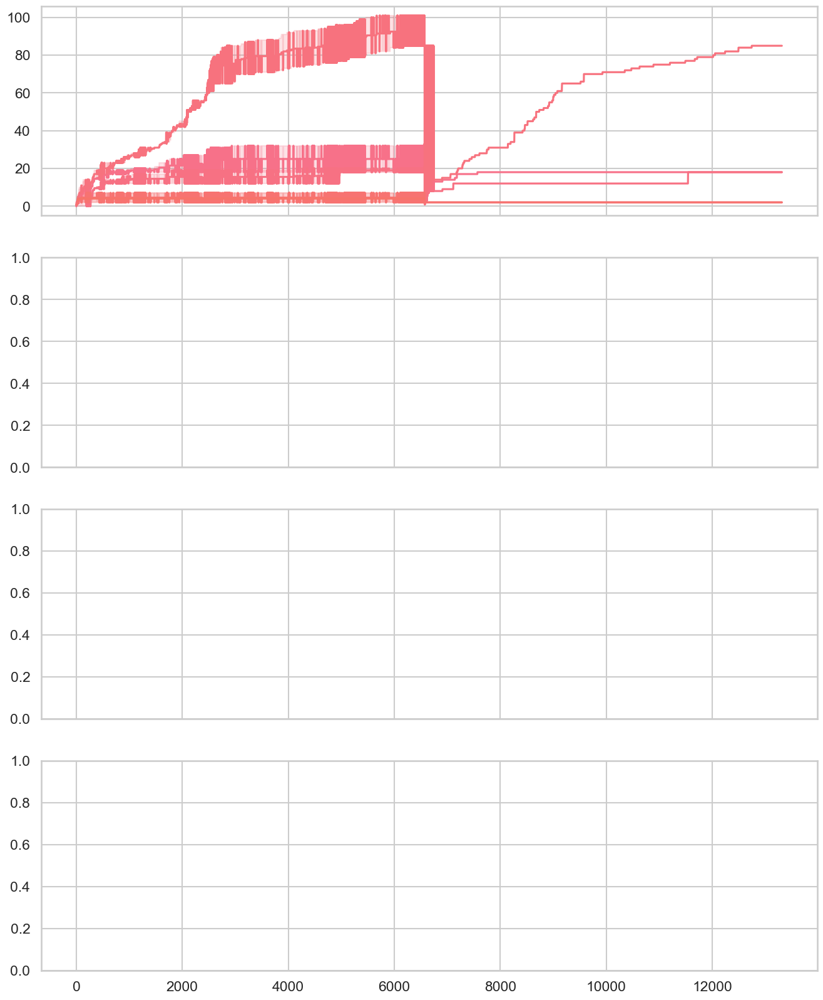

In [1571]:
plot_network_metrics(data_per_book, global_data)

In [1522]:
import dash
from dash import dcc, html
from dash.dependencies import Input, Output
import plotly.graph_objs as go
import networkx as nx

app = dash.Dash(__name__)

# Example: all book ids
book_ids = list(data_per_book.keys()) + ["Global"]

app.layout = html.Div([
    html.H1("Harry Potter Network Evolution Dashboard"),
    
    html.Div([
        html.Label("Select Book / Global"),
        dcc.Dropdown(id="book_dropdown", options=[{"label": b, "value": b} for b in book_ids], value=book_ids[0]),
        html.Label("Choose Type"),
        dcc.RadioItems(id="type_radio", options=[{"label":"Line","value":"lines"},{"label":"Chapter","value":"chapters"}], value="lines"),
        html.Label("Select Index"),
        dcc.Slider(id="index_slider", min=0, max=10, step=1, value=0, marks={0:"0"})
    ], style={"width":"25%", "display":"inline-block", "verticalAlign":"top", "padding":"20px"}),
    
    html.Div([
        dcc.Graph(id="network_graph"),
        html.Div(id="metrics_output")
    ], style={"width":"70%", "display":"inline-block", "verticalAlign":"top"})
])

@app.callback(
    Output("index_slider", "max"),
    Output("index_slider", "marks"),
    Input("book_dropdown", "value"),
    Input("type_radio", "value")
)
def update_slider(book, typ):
    if book == "Global":
        data = global_data[typ]
    else:
        data = data_per_book[book][typ]

    indices = list(data.keys())
    marks = {i:str(i) for i in indices}
    return max(indices), marks

@app.callback(
    Output("network_graph", "figure"),
    Output("metrics_output", "children"),
    Input("book_dropdown", "value"),
    Input("type_radio", "value"),
    Input("index_slider", "value")
)
def update_graph(book, typ, idx):
    if book == "Global":
        G, metrics = global_data[typ][idx]
    else:
        G, metrics = data_per_book[book][typ][idx]

    # Plot network
    pos = nx.spring_layout(G, seed=42)
    edge_trace = go.Scatter(
        x=[],
        y=[],
        line=dict(width=0.5, color='#888'),
        hoverinfo='none',
        mode='lines'
    )
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace['x'] += (x0, x1, None)
        edge_trace['y'] += (y0, y1, None)

    node_trace = go.Scatter(
        x=[],
        y=[],
        text=[],
        mode='markers+text',
        hoverinfo='text',
        marker=dict(
            showscale=True,
            colorscale='YlGnBu',
            size=10,
            color=[],
            colorbar=dict(thickness=15, title='Degree', xanchor='left', titleside='right')
        )
    )

    for node in G.nodes():
        x, y = pos[node]
        node_trace['x'] += (x,)
        node_trace['y'] += (y,)
        node_trace['marker']['color'] += (G.degree(node),)
        node_trace['text'] += (f"{node}<br>Degree: {G.degree(node)}",)

    fig = go.Figure(data=[edge_trace, node_trace],
                    layout=go.Layout(
                        title=f"Network at {typ[:-1]} {idx}",
                        showlegend=False,
                        hovermode='closest',
                        margin=dict(b=20,l=5,r=5,t=40),
                        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False)
                    ))

    # Display metrics
    metrics_text = [f"{k}: {v}" for k,v in metrics[0].iloc[0].items()]
    metrics_html = html.Ul([html.Li(m) for m in metrics_text])

    return fig, metrics_html

if __name__ == "__main__":
    app.run_server(debug=True)